In [5]:
import math
import numpy as np
import scipy.integrate as integrate
import matplotlib.pyplot as plt
import pandas as pd
from sys import maxsize 
from itertools import permutations
from mpl_toolkits.mplot3d import Axes3D

# DATA (87 Terrestrial Exoplanets and 20 Gas Giants in 62 Systems)

## Nearby Habitable Exoplanets: Part 1, 0-20 Lightyears (42 Planets in 20 Systems)

In [3]:
p1   = {"Planet": "Mercury",            "Mass (Earth)": 0.055, "Radius (Earth)": 0.383, "Gravity (Earth)": 0.377, "Density (g/cm^3)": 5.424, "Area (Earth)": 0.147, "Equilibrium Temperature (K)": 431.00, "Semi-Major Axis (AU)": 0.387,  "Orbital Period (days)": 87.97,  "Eccentricity": 0.2056, "Surface Water Ratio": 0.280, "Avg. Star Angular Diameter (deg)": 1.429, "L1 Distance (km)": 319149,  "Escape Velocity (km/s)": 4.25,  "Star": "Sol",              "Star Mass (sun)": 1.000, "Star Radius (sun)": 1.000, "Star Temperature (K)": 5778, "Spectral Type": "G2V",   "Distance (lightyears)": 0,     "Right Ascension (degrees)": 0,     "Declination (degrees)": 0}
p2   = {"Planet": "Venus",              "Mass (Earth)": 0.815, "Radius (Earth)": 0.950, "Gravity (Earth)": 0.903, "Density (g/cm^3)": 5.238, "Area (Earth)": 0.903, "Equilibrium Temperature (K)": 300.00, "Semi-Major Axis (AU)": 0.723,  "Orbital Period (days)": 224.70, "Eccentricity": 0.0068, "Surface Water Ratio": 0.650, "Avg. Star Angular Diameter (deg)": 0.765, "L1 Distance (km)": 1461834, "Escape Velocity (km/s)": 10.36, "Star": "Sol",              "Star Mass (sun)": 1.000, "Star Radius (sun)": 1.000, "Star Temperature (K)": 5778, "Spectral Type": "G2V",   "Distance (lightyears)": 0,     "Right Ascension (degrees)": 0,     "Declination (degrees)": 0}
p3   = {"Planet": "Earth",              "Mass (Earth)": 1.000, "Radius (Earth)": 1.000, "Gravity (Earth)": 1.000, "Density (g/cm^3)": 5.510, "Area (Earth)": 1.000, "Equilibrium Temperature (K)": 255.00, "Semi-Major Axis (AU)": 1.00,   "Orbital Period (days)": 365.25, "Eccentricity": 0.0167, "Surface Water Ratio": 0.710, "Avg. Star Angular Diameter (deg)": 0.553, "L1 Distance (km)": 2164582, "Escape Velocity (km/s)": 11.18, "Star": "Sol",              "Star Mass (sun)": 1.000, "Star Radius (sun)": 1.000, "Star Temperature (K)": 5778, "Spectral Type": "G2V",   "Distance (lightyears)": 0,     "Right Ascension (degrees)": 0,     "Declination (degrees)": 0}
p4   = {"Planet": "Mars",               "Mass (Earth)": 0.107, "Radius (Earth)": 0.532, "Gravity (Earth)": 0.379, "Density (g/cm^3)": 3.930, "Area (Earth)": 0.283, "Equilibrium Temperature (K)": 215.00, "Semi-Major Axis (AU)": 1.524,  "Orbital Period (days)": 686.98, "Eccentricity": 0.0934, "Surface Water Ratio": 0.340, "Avg. Star Angular Diameter (deg)": 0.363, "L1 Distance (km)": 1568052, "Escape Velocity (km/s)": 5.02,  "Star": "Sol",              "Star Mass (sun)": 1.000, "Star Radius (sun)": 1.000, "Star Temperature (K)": 5778, "Spectral Type": "G2V",   "Distance (lightyears)": 0,     "Right Ascension (degrees)": 0,     "Declination (degrees)": 0}
p5   = {"Planet": "Proxima Centauri d", "Mass (Earth)": 0.290, "Radius (Earth)": 0.700, "Gravity (Earth)": 0.592, "Density (g/cm^3)": 4.659, "Area (Earth)": 0.490, "Equilibrium Temperature (K)": 291.98, "Semi-Major Axis (AU)": 0.0288, "Orbital Period (days)": 5.15,   "Eccentricity": 0,      "Surface Water Ratio": 0.422, "Avg. Star Angular Diameter (deg)": 2.707, "L1 Distance (km)": 83658,   "Escape Velocity (km/s)": 7.20,  "Star": "Proxima Centauri", "Star Mass (sun)": 0.120, "Star Radius (sun)": 0.141, "Star Temperature (K)": 2900, "Spectral Type": "M5.5V", "Distance (lightyears)": 4.22,  "Right Ascension (degrees)": 219.0, "Declination (degrees)": -60.8}
p6   = {"Planet": "Proxima Centauri b", "Mass (Earth)": 1.170, "Radius (Earth)": 1.040, "Gravity (Earth)": 1.082, "Density (g/cm^3)": 5.731, "Area (Earth)": 1.082, "Equilibrium Temperature (K)": 223.46, "Semi-Major Axis (AU)": 0.049,  "Orbital Period (days)": 11.18,  "Eccentricity": 0.35,   "Surface Water Ratio": 0.722, "Avg. Star Angular Diameter (deg)": 1.592, "L1 Distance (km)": 226589,  "Escape Velocity (km/s)": 11.86, "Star": "Proxima Centauri", "Star Mass (sun)": 0.120, "Star Radius (sun)": 0.141, "Star Temperature (K)": 2900, "Spectral Type": "M5.5V", "Distance (lightyears)": 4.22,  "Right Ascension (degrees)": 219.0, "Declination (degrees)": -60.8}
p7   = {"Planet": "Barnard's Star d",   "Mass (Earth)": 0.220, "Radius (Earth)": 0.654, "Gravity (Earth)": 0.514, "Density (g/cm^3)": 4.334, "Area (Earth)": 0.428, "Equilibrium Temperature (K)": 443.94, "Semi-Major Axis (AU)": 0.0188, "Orbital Period (days)": 2.3407, "Eccentricity": 0.01,   "Surface Water Ratio": 0.392, "Avg. Star Angular Diameter (deg)": 5.285, "L1 Distance (km)": 31246,   "Escape Velocity (km/s)": 6.49,  "Star": "Barnard's Star",   "Star Mass (sun)": 0.162, "Star Radius (sun)": 0.187, "Star Temperature (K)": 3195, "Spectral Type": "M4V",   "Distance (lightyears)": 5.96,  "Right Ascension (degrees)": 269.5, "Declination (degrees)": 4.69}
p8   = {"Planet": "Barnard's Star b",   "Mass (Earth)": 0.370, "Radius (Earth)": 0.757, "Gravity (Earth)": 0.646, "Density (g/cm^3)": 4.700, "Area (Earth)": 0.573, "Equilibrium Temperature (K)": 401.89, "Semi-Major Axis (AU)": 0.0229, "Orbital Period (days)": 3.1533, "Eccentricity": 0.16,   "Surface Water Ratio": 0.476, "Avg. Star Angular Diameter (deg)": 4.332, "L1 Distance (km)": 45341,   "Escape Velocity (km/s)": 7.82,  "Star": "Barnard's Star",   "Star Mass (sun)": 0.162, "Star Radius (sun)": 0.187, "Star Temperature (K)": 3195, "Spectral Type": "M4V",   "Distance (lightyears)": 5.96,  "Right Ascension (degrees)": 269.5, "Declination (degrees)": 4.69}
p9   = {"Planet": "Barnard's Star c",   "Mass (Earth)": 0.310, "Radius (Earth)": 0.720, "Gravity (Earth)": 0.598, "Density (g/cm^3)": 4.576, "Area (Earth)": 0.518, "Equilibrium Temperature (K)": 367.73, "Semi-Major Axis (AU)": 0.0274, "Orbital Period (days)": 4.1243, "Eccentricity": 0.01,   "Surface Water Ratio": 0.436, "Avg. Star Angular Diameter (deg)": 3.628, "L1 Distance (km)": 51054,   "Escape Velocity (km/s)": 7.34,  "Star": "Barnard's Star",   "Star Mass (sun)": 0.162, "Star Radius (sun)": 0.187, "Star Temperature (K)": 3195, "Spectral Type": "M4V",   "Distance (lightyears)": 5.96,  "Right Ascension (degrees)": 269.5, "Declination (degrees)": 4.69}
p10  = {"Planet": "Barnard's Star e",   "Mass (Earth)": 0.170, "Radius (Earth)": 0.609, "Gravity (Earth)": 0.458, "Density (g/cm^3)": 4.147, "Area (Earth)": 0.371, "Equilibrium Temperature (K)": 311.85, "Semi-Major Axis (AU)": 0.0381, "Orbital Period (days)": 6.7377, "Eccentricity": 0.01,   "Surface Water Ratio": 0.367, "Avg. Star Angular Diameter (deg)": 2.609, "L1 Distance (km)": 58108,   "Escape Velocity (km/s)": 5.91,  "Star": "Barnard's Star",   "Star Mass (sun)": 0.162, "Star Radius (sun)": 0.187, "Star Temperature (K)": 3195, "Spectral Type": "M4V",   "Distance (lightyears)": 5.96,  "Right Ascension (degrees)": 269.5, "Declination (degrees)": 4.69}
p11  = {"Planet": "Lalande 21185 b",    "Mass (Earth)": 3.810, "Radius (Earth)": 1.450, "Gravity (Earth)": 1.812, "Density (g/cm^3)": 6.886, "Area (Earth)": 2.103, "Equilibrium Temperature (K)": 401.62, "Semi-Major Axis (AU)": 0.0695, "Orbital Period (days)": 9.87,   "Eccentricity": 0,      "Surface Water Ratio": 0.857, "Avg. Star Angular Diameter (deg)": 3.127, "L1 Distance (km)": 304379,  "Escape Velocity (km/s)": 18.12, "Star": "Lalande 21185",    "Star Mass (sun)": 0.460, "Star Radius (sun)": 0.393, "Star Temperature (K)": 3828, "Spectral Type": "M1.5V", "Distance (lightyears)": 8.32,  "Right Ascension (degrees)": 165.8, "Declination (degrees)": 36.0}
p12  = {"Planet": "Lalande 21185 d",    "Mass (Earth)": 3.890, "Radius (Earth)": 1.463, "Gravity (Earth)": 1.817, "Density (g/cm^3)": 6.845, "Area (Earth)": 2.140, "Equilibrium Temperature (K)": 136.61, "Semi-Major Axis (AU)": 0.5141, "Orbital Period (days)": 215.62, "Eccentricity": 0.15,   "Surface Water Ratio": 0.859, "Avg. Star Angular Diameter (deg)": 0.406, "L1 Distance (km)": 1572279, "Escape Velocity (km/s)": 18.23, "Star": "Lalande 21185",    "Star Mass (sun)": 0.460, "Star Radius (sun)": 0.393, "Star Temperature (K)": 3828, "Spectral Type": "M1.5V", "Distance (lightyears)": 8.32,  "Right Ascension (degrees)": 165.8, "Declination (degrees)": 36.0}
p13  = {"Planet": "Gliese 887 f",       "Mass (Earth)": 0.470, "Radius (Earth)": 0.800, "Gravity (Earth)": 0.730, "Density (g/cm^3)": 5.050, "Area (Earth)": 0.640, "Equilibrium Temperature (K)": 686.87, "Semi-Major Axis (AU)": 0.0263, "Orbital Period (days)": 2.2166, "Eccentricity": 0,      "Surface Water Ratio": 0.531, "Avg. Star Angular Diameter (deg)": 9.480, "L1 Distance (km)": 38928,   "Escape Velocity (km/s)": 6.85,  "Star": "Gliese 887",       "Star Mass (sun)": 0.490, "Star Radius (sun)": 0.470, "Star Temperature (K)": 3688, "Spectral Type": "M1V",   "Distance (lightyears)": 10.73, "Right Ascension (degrees)": 346.5, "Declination (degrees)": -35.9}
p14  = {"Planet": "Gliese 887 e",       "Mass (Earth)": 1.460, "Radius (Earth)": 1.110, "Gravity (Earth)": 1.180, "Density (g/cm^3)": 5.880, "Area (Earth)": 1.232, "Equilibrium Temperature (K)": 545.49, "Semi-Major Axis (AU)": 0.0417, "Orbital Period (days)": 4.4249, "Eccentricity": 0,      "Surface Water Ratio": 0.756, "Avg. Star Angular Diameter (deg)": 5.987, "L1 Distance (km)": 90058,   "Escape Velocity (km/s)": 14.24, "Star": "Gliese 887",       "Star Mass (sun)": 0.490, "Star Radius (sun)": 0.470, "Star Temperature (K)": 3688, "Spectral Type": "M1V",   "Distance (lightyears)": 10.73, "Right Ascension (degrees)": 346.5, "Declination (degrees)": -35.9}
p13  = {"Planet": "Gliese 887 b",       "Mass (Earth)": 4.200, "Radius (Earth)": 1.490, "Gravity (Earth)": 1.892, "Density (g/cm^3)": 6.996, "Area (Earth)": 2.220, "Equilibrium Temperature (K)": 468.00, "Semi-Major Axis (AU)": 0.0683, "Orbital Period (days)": 9.2619, "Eccentricity": 0.14,   "Surface Water Ratio": 0.864, "Avg. Star Angular Diameter (deg)": 3.822, "L1 Distance (km)": 301232,  "Escape Velocity (km/s)": 18.77, "Star": "Gliese 887",       "Star Mass (sun)": 0.490, "Star Radius (sun)": 0.470, "Star Temperature (K)": 3688, "Spectral Type": "M1V",   "Distance (lightyears)": 10.73, "Right Ascension (degrees)": 346.5, "Declination (degrees)": -35.9}
p15  = {"Planet": "Ross 128 b",         "Mass (Earth)": 1.400, "Radius (Earth)": 1.090, "Gravity (Earth)": 1.178, "Density (g/cm^3)": 5.957, "Area (Earth)": 1.188, "Equilibrium Temperature (K)": 280.26, "Semi-Major Axis (AU)": 0.0496, "Orbital Period (days)": 9.87,   "Eccentricity": 0.12,   "Surface Water Ratio": 0.747, "Avg. Star Angular Diameter (deg)": 2.197, "L1 Distance (km)": 217668,  "Escape Velocity (km/s)": 12.67, "Star": "Ross 128",         "Star Mass (sun)": 0.168, "Star Radius (sun)": 0.197, "Star Temperature (K)": 3192, "Spectral Type": "M4V",   "Distance (lightyears)": 11.03, "Right Ascension (degrees)": 176.9, "Declination (degrees)": -0.80}
p16  = {"Planet": "Gliese 725 A b",     "Mass (Earth)": 2.780, "Radius (Earth)": 1.330, "Gravity (Earth)": 1.570, "Density (g/cm^3)": 6.510, "Area (Earth)": 1.769, "Equilibrium Temperature (K)": 343.63, "Semi-Major Axis (AU)": 0.0680, "Orbital Period (days)": 11.220, "Eccentricity": 0,      "Surface Water Ratio": 0.830, "Avg. Star Angular Diameter (deg)": 2.744, "L1 Distance (km)": 207660,  "Escape Velocity (km/s)": 21.50, "Star": "Gliese 725 A",     "Star Mass (sun)": 0.330, "Star Radius (sun)": 0.351, "Star Temperature (K)": 3433, "Spectral Type": "M3V",   "Distance (lightyears)": 11.49, "Right Ascension (degrees)": 280.7, "Declination (degrees)": 59.6}
p17  = {"Planet": "Gliese 725 B b",     "Mass (Earth)": 1.202, "Radius (Earth)": 1.050, "Gravity (Earth)": 1.090, "Density (g/cm^3)": 5.721, "Area (Earth)": 1.103, "Equilibrium Temperature (K)": 470.91, "Semi-Major Axis (AU)": 0.0350, "Orbital Period (days)": 4.765,  "Eccentricity": 0,      "Surface Water Ratio": 0.727, "Avg. Star Angular Diameter (deg)": 4.252, "L1 Distance (km)": 88659,   "Escape Velocity (km/s)": 12.56, "Star": "Gliese 725 B",     "Star Mass (sun)": 0.250, "Star Radius (sun)": 0.280, "Star Temperature (K)": 3779, "Spectral Type": "M3.5V", "Distance (lightyears)": 11.49, "Right Ascension (degrees)": 280.7, "Declination (degrees)": 59.6}
p18  = {"Planet": "Gliese 15 A b",      "Mass (Earth)": 3.000, "Radius (Earth)": 1.360, "Gravity (Earth)": 1.622, "Density (g/cm^3)": 6.571, "Area (Earth)": 1.850, "Equilibrium Temperature (K)": 363.87, "Semi-Major Axis (AU)": 0.072,  "Orbital Period (days)": 11.44,  "Eccentricity": 0.09,   "Surface Water Ratio": 0.837, "Avg. Star Angular Diameter (deg)": 2.965, "L1 Distance (km)": 310327,  "Escape Velocity (km/s)": 16.60, "Star": "Gliese 15 A",      "Star Mass (sun)": 0.380, "Star Radius (sun)": 0.386, "Star Temperature (K)": 3567, "Spectral Type": "M2V",   "Distance (lightyears)": 11.70, "Right Ascension (degrees)": 4.60,  "Declination (degrees)": 44.0}
p19  = {"Planet": "YZ Ceti b",          "Mass (Earth)": 0.750, "Radius (Earth)": 0.920, "Gravity (Earth)": 0.886, "Density (g/cm^3)": 5.307, "Area (Earth)": 0.846, "Equilibrium Temperature (K)": 444.46, "Semi-Major Axis (AU)": 0.0156, "Orbital Period (days)": 1.97,   "Eccentricity": 0,      "Surface Water Ratio": 0.645, "Avg. Star Angular Diameter (deg)": 6.022, "L1 Distance (km)": 60563,   "Escape Velocity (km/s)": 10.09, "Star": "YZ Ceti",          "Star Mass (sun)": 0.130, "Star Radius (sun)": 0.170, "Star Temperature (K)": 3056, "Spectral Type": "M4.5V", "Distance (lightyears)": 11.74, "Right Ascension (degrees)": 18.1,  "Declination (degrees)": -17.0}
p20  = {"Planet": "YZ Ceti c",          "Mass (Earth)": 0.980, "Radius (Earth)": 0.990, "Gravity (Earth)": 1.000, "Density (g/cm^3)": 5.565, "Area (Earth)": 0.980, "Equilibrium Temperature (K)": 383.99, "Semi-Major Axis (AU)": 0.0209, "Orbital Period (days)": 3.06,   "Eccentricity": 0.04,   "Surface Water Ratio": 0.693, "Avg. Star Angular Diameter (deg)": 4.497, "L1 Distance (km)": 88705,   "Escape Velocity (km/s)": 11.12, "Star": "YZ Ceti",          "Star Mass (sun)": 0.130, "Star Radius (sun)": 0.170, "Star Temperature (K)": 3056, "Spectral Type": "M4.5V", "Distance (lightyears)": 11.74, "Right Ascension (degrees)": 18.1,  "Declination (degrees)": -17.0}
p21  = {"Planet": "YZ Ceti d",          "Mass (Earth)": 1.140, "Radius (Earth)": 1.030, "Gravity (Earth)": 1.075, "Density (g/cm^3)": 5.748, "Area (Earth)": 1.061, "Equilibrium Temperature (K)": 334.15, "Semi-Major Axis (AU)": 0.0276, "Orbital Period (days)": 4.66,   "Eccentricity": 0.129,  "Surface Water Ratio": 0.717, "Avg. Star Angular Diameter (deg)": 3.406, "L1 Distance (km)": 123198,  "Escape Velocity (km/s)": 11.76, "Star": "YZ Ceti",          "Star Mass (sun)": 0.130, "Star Radius (sun)": 0.170, "Star Temperature (K)": 3056, "Spectral Type": "M4.5V", "Distance (lightyears)": 11.74, "Right Ascension (degrees)": 18.1,  "Declination (degrees)": -17.0}
p22  = {"Planet": "Tau Ceti g",         "Mass (Earth)": 1.800, "Radius (Earth)": 1.170, "Gravity (Earth)": 1.315, "Density (g/cm^3)": 6.193, "Area (Earth)": 1.369, "Equilibrium Temperature (K)": 575.98, "Semi-Major Axis (AU)": 0.1329, "Orbital Period (days)": 20.00,  "Eccentricity": 0.06,   "Surface Water Ratio": 0.780, "Avg. Star Angular Diameter (deg)": 3.300, "L1 Distance (km)": 379667 , "Escape Velocity (km/s)": 13.87, "Star": "Tau Ceti",         "Star Mass (sun)": 0.783, "Star Radius (sun)": 0.793, "Star Temperature (K)": 5344, "Spectral Type": "G8.5V", "Distance (lightyears)": 11.90, "Right Ascension (degrees)": 26.0,  "Declination (degrees)": -15.9}
p23  = {"Planet": "Tau Ceti h",         "Mass (Earth)": 1.800, "Radius (Earth)": 1.170, "Gravity (Earth)": 1.315, "Density (g/cm^3)": 6.193, "Area (Earth)": 1.369, "Equilibrium Temperature (K)": 425.32, "Semi-Major Axis (AU)": 0.243,  "Orbital Period (days)": 49.41,  "Eccentricity": 0.23,   "Surface Water Ratio": 0.780, "Avg. Star Angular Diameter (deg)": 1.805, "L1 Distance (km)": 694199,  "Escape Velocity (km/s)": 13.87, "Star": "Tau Ceti",         "Star Mass (sun)": 0.783, "Star Radius (sun)": 0.793, "Star Temperature (K)": 5344, "Spectral Type": "G8.5V", "Distance (lightyears)": 11.90, "Right Ascension (degrees)": 26.0,  "Declination (degrees)": -15.9}
p24  = {"Planet": "Tau Ceti f",         "Mass (Earth)": 3.900, "Radius (Earth)": 1.460, "Gravity (Earth)": 1.830, "Density (g/cm^3)": 6.905, "Area (Earth)": 2.132, "Equilibrium Temperature (K)": 181.52, "Semi-Major Axis (AU)": 1.334,  "Orbital Period (days)": 636.00, "Eccentricity": 0.16,   "Surface Water Ratio": 0.859, "Avg. Star Angular Diameter (deg)": 0.329, "L1 Distance (km)": 4931330, "Escape Velocity (km/s)": 18.27, "Star": "Tau Ceti",         "Star Mass (sun)": 0.783, "Star Radius (sun)": 0.793, "Star Temperature (K)": 5344, "Spectral Type": "G8.5V", "Distance (lightyears)": 11.90, "Right Ascension (degrees)": 26.0,  "Declination (degrees)": -15.9}
p25  = {"Planet": "Gliese 1061 b",      "Mass (Earth)": 1.370, "Radius (Earth)": 1.090, "Gravity (Earth)": 1.153, "Density (g/cm^3)": 5.829, "Area (Earth)": 1.188, "Equilibrium Temperature (K)": 359.11, "Semi-Major Axis (AU)": 0.021,  "Orbital Period (days)": 3.204,  "Eccentricity": 0.31,   "Surface Water Ratio": 0.747, "Avg. Star Angular Diameter (deg)": 4.212, "L1 Distance (km)": 102354,  "Escape Velocity (km/s)": 12.53, "Star": "Gliese 1061",      "Star Mass (sun)": 0.120, "Star Radius (sun)": 0.160, "Star Temperature (K)": 2953, "Spectral Type": "M5.5V", "Distance (lightyears)": 11.97, "Right Ascension (degrees)": 54.0,  "Declination (degrees)": -44.5}
p26  = {"Planet": "Gliese 1061 c",      "Mass (Earth)": 1.700, "Radius (Earth)": 1.160, "Gravity (Earth)": 1.263, "Density (g/cm^3)": 6.001, "Area (Earth)": 1.346, "Equilibrium Temperature (K)": 278.16, "Semi-Major Axis (AU)": 0.035,  "Orbital Period (days)": 6.689,  "Eccentricity": 0.29,   "Surface Water Ratio": 0.777, "Avg. Star Angular Diameter (deg)": 2.528, "L1 Distance (km)": 183315,  "Escape Velocity (km/s)": 13.53, "Star": "Gliese 1061",      "Star Mass (sun)": 0.120, "Star Radius (sun)": 0.160, "Star Temperature (K)": 2953, "Spectral Type": "M5.5V", "Distance (lightyears)": 11.97, "Right Ascension (degrees)": 54.0,  "Declination (degrees)": -44.5}
p27  = {"Planet": "Gliese 1061 d",      "Mass (Earth)": 1.600, "Radius (Earth)": 1.140, "Gravity (Earth)": 1.231, "Density (g/cm^3)": 5.951, "Area (Earth)": 1.300, "Equilibrium Temperature (K)": 223.94, "Semi-Major Axis (AU)": 0.054,  "Orbital Period (days)": 13.03,  "Eccentricity": 0.53,   "Surface Water Ratio": 0.769, "Avg. Star Angular Diameter (deg)": 1.639, "L1 Distance (km)": 277171,  "Escape Velocity (km/s)": 13.24, "Star": "Gliese 1061",      "Star Mass (sun)": 0.120, "Star Radius (sun)": 0.160, "Star Temperature (K)": 2953, "Spectral Type": "M5.5V", "Distance (lightyears)": 11.97, "Right Ascension (degrees)": 54.0,  "Declination (degrees)": -44.5}
p28  = {"Planet": "Luyten's Star c",    "Mass (Earth)": 1.180, "Radius (Earth)": 1.040, "Gravity (Earth)": 1.091, "Density (g/cm^3)": 5.780, "Area (Earth)": 1.082, "Equilibrium Temperature (K)": 422.16, "Semi-Major Axis (AU)": 0.0365, "Orbital Period (days)": 4.72,   "Eccentricity": 0.17,   "Surface Water Ratio": 0.722, "Avg. Star Angular Diameter (deg)": 4.438, "L1 Distance (km)": 126133,  "Escape Velocity (km/s)": 11.91, "Star": "Luyten's Star",    "Star Mass (sun)": 0.290, "Star Radius (sun)": 0.293, "Star Temperature (K)": 3382, "Spectral Type": "M3.5V", "Distance (lightyears)": 12.40, "Right Ascension (degrees)": 111.9, "Declination (degrees)": 5.23}
p29  = {"Planet": "Luyten's Star b",    "Mass (Earth)": 2.900, "Radius (Earth)": 1.340, "Gravity (Earth)": 1.615, "Density (g/cm^3)": 6.641, "Area (Earth)": 1.796, "Equilibrium Temperature (K)": 267.21, "Semi-Major Axis (AU)": 0.0911, "Orbital Period (days)": 18.65,  "Eccentricity": 0.1,    "Surface Water Ratio": 0.832, "Avg. Star Angular Diameter (deg)": 1.779, "L1 Distance (km)": 424840,  "Escape Velocity (km/s)": 16.45, "Star": "Luyten's Star",    "Star Mass (sun)": 0.290, "Star Radius (sun)": 0.293, "Star Temperature (K)": 3382, "Spectral Type": "M3.5V", "Distance (lightyears)": 12.40, "Right Ascension (degrees)": 111.9, "Declination (degrees)": 5.23}
p30  = {"Planet": "Teegarden's Star b", "Mass (Earth)": 1.050, "Radius (Earth)": 1.010, "Gravity (Earth)": 1.029, "Density (g/cm^3)": 5.615, "Area (Earth)": 1.020, "Equilibrium Temperature (K)": 263.63, "Semi-Major Axis (AU)": 0.0252, "Orbital Period (days)": 4.91,   "Eccentricity": 0.03,   "Surface Water Ratio": 0.705, "Avg. Star Angular Diameter (deg)": 2.348, "L1 Distance (km)": 124177,  "Escape Velocity (km/s)": 11.40, "Star": "Teegarden's Star", "Star Mass (sun)": 0.089, "Star Radius (sun)": 0.107, "Star Temperature (K)": 2904, "Spectral Type": "M7V",   "Distance (lightyears)": 12.58, "Right Ascension (degrees)": 43.3,  "Declination (degrees)": 16.9}
p31  = {"Planet": "Teegarden's Star c", "Mass (Earth)": 1.110, "Radius (Earth)": 1.020, "Gravity (Earth)": 1.067, "Density (g/cm^3)": 5.763, "Area (Earth)": 1.040, "Equilibrium Temperature (K)": 198.84, "Semi-Major Axis (AU)": 0.0443, "Orbital Period (days)": 11.409, "Eccentricity": 0.04,   "Surface Water Ratio": 0.711, "Avg. Star Angular Diameter (deg)": 1.336, "L1 Distance (km)": 222376,  "Escape Velocity (km/s)": 11.66, "Star": "Teegarden's Star", "Star Mass (sun)": 0.089, "Star Radius (sun)": 0.107, "Star Temperature (K)": 2904, "Spectral Type": "M7V",   "Distance (lightyears)": 12.58, "Right Ascension (degrees)": 43.3,  "Declination (degrees)": 16.9}
p32  = {"Planet": "Teegarden's Star d", "Mass (Earth)": 0.820, "Radius (Earth)": 0.946, "Gravity (Earth)": 0.916, "Density (g/cm^3)": 5.337, "Area (Earth)": 0.895, "Equilibrium Temperature (K)": 148.90, "Semi-Major Axis (AU)": 0.0791, "Orbital Period (days)": 26.13,  "Eccentricity": 0.07,   "Surface Water Ratio": 0.664, "Avg. Star Angular Diameter (deg)": 0.719, "L1 Distance (km)": 91479,   "Escape Velocity (km/s)": 10.41, "Star": "Teegarden's Star", "Star Mass (sun)": 0.089, "Star Radius (sun)": 0.107, "Star Temperature (K)": 2904, "Spectral Type": "M7V",   "Distance (lightyears)": 12.58, "Right Ascension (degrees)": 43.3,  "Declination (degrees)": 16.9}
p33  = {"Planet": "Wolf 1061 b",        "Mass (Earth)": 1.400, "Radius (Earth)": 1.090, "Gravity (Earth)": 1.178, "Density (g/cm^3)": 5.957, "Area (Earth)": 1.188, "Equilibrium Temperature (K)": 398.82, "Semi-Major Axis (AU)": 0.0355, "Orbital Period (days)": 4.89,   "Eccentricity": 0,      "Surface Water Ratio": 0.747, "Avg. Star Angular Diameter (deg)": 4.049, "L1 Distance (km)": 136458,  "Escape Velocity (km/s)": 12.67, "Star": "Wolf 1061",        "Star Mass (sun)": 0.250, "Star Radius (sun)": 0.260, "Star Temperature (K)": 3345, "Spectral Type": "M3.5V", "Distance (lightyears)": 14.00, "Right Ascension (degrees)": 247.6, "Declination (degrees)": -12.7}
p34  = {"Planet": "Wolf 1061 c",        "Mass (Earth)": 4.300, "Radius (Earth)": 1.500, "Gravity (Earth)": 1.911, "Density (g/cm^3)": 7.020, "Area (Earth)": 2.250, "Equilibrium Temperature (K)": 258.81, "Semi-Major Axis (AU)": 0.0843, "Orbital Period (days)": 17.87,  "Eccentricity": 0.19,   "Surface Water Ratio": 0.866, "Avg. Star Angular Diameter (deg)": 1.706, "L1 Distance (km)": 471025,  "Escape Velocity (km/s)": 18.93, "Star": "Wolf 1061",        "Star Mass (sun)": 0.250, "Star Radius (sun)": 0.260, "Star Temperature (K)": 3345, "Spectral Type": "M3.5V", "Distance (lightyears)": 14.00, "Right Ascension (degrees)": 247.6, "Declination (degrees)": -12.7}
p35  = {"Planet": "Gliese 1002 b",      "Mass (Earth)": 1.080, "Radius (Earth)": 1.022, "Gravity (Earth)": 1.057, "Density (g/cm^3)": 5.697, "Area (Earth)": 1.044, "Equilibrium Temperature (K)": 230.67, "Semi-Major Axis (AU)": 0.0457, "Orbital Period (days)": 10.347, "Eccentricity": 0,      "Surface Water Ratio": 0.712, "Avg. Star Angular Diameter (deg)": 1.594, "L1 Distance (km)": 142669,  "Escape Velocity (km/s)": 11.50, "Star": "Gliese 1002",      "Star Mass (sun)": 0.120, "Star Radius (sun)": 0.137, "Star Temperature (K)": 3024, "Spectral Type": "M5.5V", "Distance (lightyears)": 15.81, "Right Ascension (degrees)": 1.68,  "Declination (degrees)": -7.54}
p36  = {"Planet": "Gliese 1002 c",      "Mass (Earth)": 1.360, "Radius (Earth)": 1.090, "Gravity (Earth)": 1.145, "Density (g/cm^3)": 5.786, "Area (Earth)": 1.188, "Equilibrium Temperature (K)": 181.52, "Semi-Major Axis (AU)": 0.0738, "Orbital Period (days)": 21.202, "Eccentricity": 0,      "Surface Water Ratio": 0.747, "Avg. Star Angular Diameter (deg)": 0.987, "L1 Distance (km)": 248795,  "Escape Velocity (km/s)": 12.50, "Star": "Gliese 1002",      "Star Mass (sun)": 0.120, "Star Radius (sun)": 0.137, "Star Temperature (K)": 3024, "Spectral Type": "M5.5V", "Distance (lightyears)": 15.81, "Right Ascension (degrees)": 1.68,  "Declination (degrees)": -7.54}
p37  = {"Planet": "Gliese 3323 b",      "Mass (Earth)": 2.000, "Radius (Earth)": 1.210, "Gravity (Earth)": 1.366, "Density (g/cm^3)": 6.221, "Area (Earth)": 1.464, "Equilibrium Temperature (K)": 265.09, "Semi-Major Axis (AU)": 0.0328, "Orbital Period (days)": 5.3636, "Eccentricity": 0.23,   "Surface Water Ratio": 0.795, "Avg. Star Angular Diameter (deg)": 2.007, "L1 Distance (km)": 163422,  "Escape Velocity (km/s)": 14.37, "Star": "Gliese 3323",      "Star Mass (sun)": 0.164, "Star Radius (sun)": 0.119, "Star Temperature (K)": 3159, "Spectral Type": "M4V",   "Distance (lightyears)": 17.55, "Right Ascension (degrees)": 75.5,  "Declination (degrees)": -6.95}
p38  = {"Planet": "Gliese 3323 c",      "Mass (Earth)": 2.300, "Radius (Earth)": 1.260, "Gravity (Earth)": 1.449, "Density (g/cm^3)": 6.335, "Area (Earth)": 1.588, "Equilibrium Temperature (K)": 135.25, "Semi-Major Axis (AU)": 0.126,  "Orbital Period (days)": 40.54,  "Eccentricity": 0.17,   "Surface Water Ratio": 0.811, "Avg. Star Angular Diameter (deg)": 0.522, "L1 Distance (km)": 657717,  "Escape Velocity (km/s)": 15.10, "Star": "Gliese 3323",      "Star Mass (sun)": 0.164, "Star Radius (sun)": 0.119, "Star Temperature (K)": 3159, "Spectral Type": "M4V",   "Distance (lightyears)": 17.55, "Right Ascension (degrees)": 75.5,  "Declination (degrees)": -6.95}
p39  = {"Planet": "Gliese 251 b",       "Mass (Earth)": 4.000, "Radius (Earth)": 1.470, "Gravity (Earth)": 1.851, "Density (g/cm^3)": 6.938, "Area (Earth)": 2.161, "Equilibrium Temperature (K)": 320.72, "Semi-Major Axis (AU)": 0.0818, "Orbital Period (days)": 14.238, "Eccentricity": 0.1,    "Surface Water Ratio": 0.861, "Avg. Star Angular Diameter (deg)": 2.434, "L1 Distance (km)": 395106,  "Escape Velocity (km/s)": 18.44, "Star": "Gliese 251",       "Star Mass (sun)": 0.360, "Star Radius (sun)": 0.360, "Star Temperature (K)": 3451, "Spectral Type": "M3V",   "Distance (lightyears)": 18.21, "Right Ascension (degrees)": 103.7, "Declination (degrees)": 33.3}
p40  = {"Planet": "Gliese 588 b",       "Mass (Earth)": 2.400, "Radius (Earth)": 1.270, "Gravity (Earth)": 1.488, "Density (g/cm^3)": 6.456, "Area (Earth)": 1.613, "Equilibrium Temperature (K)": 490.20, "Semi-Major Axis (AU)": 0.049,  "Orbital Period (days)": 5.8084, "Eccentricity": 0.04,   "Surface Water Ratio": 0.814, "Avg. Star Angular Diameter (deg)": 5.415, "L1 Distance (km)": 183959,  "Escape Velocity (km/s)": 15.37, "Star": "Gliese 588",       "Star Mass (sun)": 0.460, "Star Radius (sun)": 0.480, "Star Temperature (K)": 3555, "Spectral Type": "M2.5V", "Distance (lightyears)": 19.34, "Right Ascension (degrees)": 233.1, "Declination (degrees)": -41.3}
p41  = {"Planet": "82 G Eridani b",     "Mass (Earth)": 2.000, "Radius (Earth)": 1.214, "Gravity (Earth)": 1.357, "Density (g/cm^3)": 6.159, "Area (Earth)": 1.474, "Equilibrium Temperature (K)": 634.44, "Semi-Major Axis (AU)": 0.130,  "Orbital Period (days)": 18.32,  "Eccentricity": 0.09,   "Surface Water Ratio": 0.796, "Avg. Star Angular Diameter (deg)": 3.680, "L1 Distance (km)": 256620,  "Escape Velocity (km/s)": 14.36, "Star": "82 G Eridani",     "Star Mass (sun)": 0.879, "Star Radius (sun)": 0.900, "Star Temperature (K)": 5473, "Spectral Type": "G6V",   "Distance (lightyears)": 19.70, "Right Ascension (degrees)": 50.0,  "Declination (degrees)": -43.1}
p42  = {"Planet": "82 G Eridani c",     "Mass (Earth)": 4.700, "Radius (Earth)": 1.542, "Gravity (Earth)": 1.977, "Density (g/cm^3)": 7.063, "Area (Earth)": 2.378, "Equilibrium Temperature (K)": 376.06, "Semi-Major Axis (AU)": 0.370,  "Orbital Period (days)": 89.58,  "Eccentricity": 0.13,   "Surface Water Ratio": 0.873, "Avg. Star Angular Diameter (deg)": 1.293, "L1 Distance (km)": 971043,  "Escape Velocity (km/s)": 19.53, "Star": "82 G Eridani",     "Star Mass (sun)": 0.879, "Star Radius (sun)": 0.900, "Star Temperature (K)": 5473, "Spectral Type": "G6V",   "Distance (lightyears)": 19.70, "Right Ascension (degrees)": 50.0,  "Declination (degrees)": -43.1}

## Nearby Habitable Exoplanets: Part 2, 20-50 Lightyears (45 Planets in 25 Systems)

In [2]:
p43  = {"Planet": "Gliese 581 e",       "Mass (Earth)": 1.940, "Radius (Earth)": 1.200, "Gravity (Earth)": 1.347, "Density (g/cm^3)": 6.186, "Area (Earth)": 1.440, "Equilibrium Temperature (K)": 502.66, "Semi-Major Axis (AU)": 0.0281, "Orbital Period (days)": 3.149,  "Eccentricity": 0.06,   "Surface Water Ratio": 0.792, "Avg. Star Angular Diameter (deg)": 5.900, "L1 Distance (km)": 112088,  "Escape Velocity (km/s)": 14.22, "Star": "Gliese 581",       "Star Mass (sun)": 0.310, "Star Radius (sun)": 0.300, "Star Temperature (K)": 3498, "Spectral Type": "M2.5V", "Distance (lightyears)": 20.30, "Right Ascension (degrees)": 229.9, "Declination (degrees)": -7.72}
p44  = {"Planet": "Gliese 625 b",       "Mass (Earth)": 2.800, "Radius (Earth)": 1.330, "Gravity (Earth)": 1.583, "Density (g/cm^3)": 6.558, "Area (Earth)": 1.769, "Equilibrium Temperature (K)": 306.53, "Semi-Major Axis (AU)": 0.0784, "Orbital Period (days)": 14.628, "Eccentricity": 0.13,   "Surface Water Ratio": 0.830, "Avg. Star Angular Diameter (deg)": 2.187, "L1 Distance (km)": 357302,  "Escape Velocity (km/s)": 16.22, "Star": "Gliese 625",       "Star Mass (sun)": 0.300, "Star Radius (sun)": 0.310, "Star Temperature (K)": 3499, "Spectral Type": "M2V",   "Distance (lightyears)": 21.20, "Right Ascension (degrees)": 246.4, "Declination (degrees)": 54.3}
p45  = {"Planet": "Gliese 892 b",       "Mass (Earth)": 4.740, "Radius (Earth)": 1.602, "Gravity (Earth)": 1.847, "Density (g/cm^3)": 6.352, "Area (Earth)": 2.566, "Equilibrium Temperature (K)": 927.03, "Semi-Major Axis (AU)": 0.0388, "Orbital Period (days)": 3.093,  "Eccentricity": 0,      "Surface Water Ratio": 0.883, "Avg. Star Angular Diameter (deg)": 10.65, "L1 Distance (km)": 104829,  "Escape Velocity (km/s)": 19.24, "Star": "Gliese 892",       "Star Mass (sun)": 0.810, "Star Radius (sun)": 0.778, "Star Temperature (K)": 4699, "Spectral Type": "K3V",   "Distance (lightyears)": 21.35, "Right Ascension (degrees)": 349.0, "Declination (degrees)": 57.2}
p46  = {"Planet": "Gliese 892 c",       "Mass (Earth)": 4.360, "Radius (Earth)": 1.511, "Gravity (Earth)": 1.910, "Density (g/cm^3)": 6.964, "Area (Earth)": 2.283, "Equilibrium Temperature (K)": 714.59, "Semi-Major Axis (AU)": 0.0653, "Orbital Period (days)": 6.765,  "Eccentricity": 0.062,  "Surface Water Ratio": 0.868, "Avg. Star Angular Diameter (deg)": 6.332, "L1 Distance (km)": 171757,  "Escape Velocity (km/s)": 19.00, "Star": "Gliese 892",       "Star Mass (sun)": 0.810, "Star Radius (sun)": 0.778, "Star Temperature (K)": 4699, "Spectral Type": "K3V",   "Distance (lightyears)": 21.35, "Right Ascension (degrees)": 349.0, "Declination (degrees)": 57.2}
p47  = {"Planet": "LTT 1445 A b",       "Mass (Earth)": 2.200, "Radius (Earth)": 1.350, "Gravity (Earth)": 1.207, "Density (g/cm^3)": 4.927, "Area (Earth)": 1.823, "Equilibrium Temperature (K)": 395.85, "Semi-Major Axis (AU)": 0.0381, "Orbital Period (days)": 5.359,  "Eccentricity": 0.19,   "Surface Water Ratio": 0.835, "Avg. Star Angular Diameter (deg)": 4.063, "L1 Distance (km)": 168054,  "Escape Velocity (km/s)": 14.27, "Star": "LTT 1445 A",       "Star Mass (sun)": 0.260, "Star Radius (sun)": 0.280, "Star Temperature (K)": 3337, "Spectral Type": "M3V",   "Distance (lightyears)": 22.41, "Right Ascension (degrees)": 45.5,  "Declination (degrees)": -16.6}
p48  = {"Planet": "LTT 1445 A c",       "Mass (Earth)": 1.540, "Radius (Earth)": 1.150, "Gravity (Earth)": 1.164, "Density (g/cm^3)": 6.078, "Area (Earth)": 1.323, "Equilibrium Temperature (K)": 473.48, "Semi-Major Axis (AU)": 0.0266, "Orbital Period (days)": 3.124,  "Eccentricity": 0.22,   "Surface Water Ratio": 0.873, "Avg. Star Angular Diameter (deg)": 5.511, "L1 Distance (km)": 726337,  "Escape Velocity (km/s)": 12.11, "Star": "LTT 1445 A",       "Star Mass (sun)": 0.260, "Star Radius (sun)": 0.280, "Star Temperature (K)": 3337, "Spectral Type": "M3V",   "Distance (lightyears)": 22.41, "Right Ascension (degrees)": 45.5,  "Declination (degrees)": -16.6}
p49  = {"Planet": "LTT 1445 A d",       "Mass (Earth)": 2.410, "Radius (Earth)": 1.279, "Gravity (Earth)": 1.473, "Density (g/cm^3)": 6.347, "Area (Earth)": 1.636, "Equilibrium Temperature (K)": 757.37, "Semi-Major Axis (AU)": 0.0104, "Orbital Period (days)": 24.304, "Eccentricity": 0.26,   "Surface Water Ratio": 0.816, "Avg. Star Angular Diameter (deg)": 14.00, "L1 Distance (km)": 33053,   "Escape Velocity (km/s)": 15.35, "Star": "LTT 1445 A",       "Star Mass (sun)": 0.260, "Star Radius (sun)": 0.280, "Star Temperature (K)": 3337, "Spectral Type": "M3V",   "Distance (lightyears)": 21.41, "Right Ascension (degrees)": 45.5,  "Declination (degrees)": -16.6}
p50  = {"Planet": "Gliese 667 C c",     "Mass (Earth)": 3.800, "Radius (Earth)": 1.450, "Gravity (Earth)": 1.807, "Density (g/cm^3)": 6.868, "Area (Earth)": 2.103, "Equilibrium Temperature (K)": 267.30, "Semi-Major Axis (AU)": 0.125,  "Orbital Period (days)": 28.14,  "Eccentricity": 0.02,   "Surface Water Ratio": 0.857, "Avg. Star Angular Diameter (deg)": 0.872, "L1 Distance (km)": 423643,  "Escape Velocity (km/s)": 18.10, "Star": "Gliese 667 C",     "Star Mass (sun)": 0.330, "Star Radius (sun)": 0.410, "Star Temperature (K)": 3350, "Spectral Type": "M1.5V", "Distance (lightyears)": 22.70, "Right Ascension (degrees)": 259.7, "Declination (degrees)": -35}
p51  = {"Planet": "Gliese 393 b",       "Mass (Earth)": 1.900, "Radius (Earth)": 1.190, "Gravity (Earth)": 1.342, "Density (g/cm^3)": 6.212, "Area (Earth)": 1.416, "Equilibrium Temperature (K)": 448.97, "Semi-Major Axis (AU)": 0.055,  "Orbital Period (days)": 7.03,   "Eccentricity": 0.03,   "Surface Water Ratio": 0.788, "Avg. Star Angular Diameter (deg)": 1.983, "L1 Distance (km)": 137621,  "Escape Velocity (km/s)": 14.13, "Star": "Gliese 393",       "Star Mass (sun)": 0.410, "Star Radius (sun)": 0.410, "Star Temperature (K)": 3544, "Spectral Type": "M2.5V", "Distance (lightyears)": 23.00, "Right Ascension (degrees)": 157.2, "Declination (degrees)": 0.8}
p52  = {"Planet": "Gliese 1151 c",      "Mass (Earth)": 2.500, "Radius (Earth)": 1.290, "Gravity (Earth)": 1.502, "Density (g/cm^3)": 6.417, "Area (Earth)": 1.664, "Equilibrium Temperature (K)": 449.39, "Semi-Major Axis (AU)": 0.0173, "Orbital Period (days)": 2.018,  "Eccentricity": 0,      "Surface Water Ratio": 0.820, "Avg. Star Angular Diameter (deg)": 3.076, "L1 Distance (km)": 63613,   "Escape Velocity (km/s)": 15.56, "Star": "Gliese 1151",      "Star Mass (sun)": 0.170, "Star Radius (sun)": 0.200, "Star Temperature (K)": 3000, "Spectral Type": "M4.5V", "Distance (lightyears)": 26.20, "Right Ascension (degrees)": 177.7, "Declination (degrees)": 48.4}
p53  = {"Planet": "Gliese 486 b",       "Mass (Earth)": 2.820, "Radius (Earth)": 1.280, "Gravity (Earth)": 1.721, "Density (g/cm^3)": 7.409, "Area (Earth)": 1.638, "Equilibrium Temperature (K)": 666.25, "Semi-Major Axis (AU)": 0.0173, "Orbital Period (days)": 1.4671, "Eccentricity": 0.05,   "Surface Water Ratio": 0.817, "Avg. Star Angular Diameter (deg)": 5.053, "L1 Distance (km)": 53631,   "Escape Velocity (km/s)": 16.59, "Star": "Gliese 486",       "Star Mass (sun)": 0.320, "Star Radius (sun)": 0.328, "Star Temperature (K)": 3340, "Spectral Type": "M3.5V", "Distance (lightyears)": 26.30, "Right Ascension (degrees)": 192.0, "Declination (degrees)": 9.8}
p54  = {"Planet": "CD Ceti b",          "Mass (Earth)": 4.000, "Radius (Earth)": 1.470, "Gravity (Earth)": 1.851, "Density (g/cm^3)": 6.938, "Area (Earth)": 2.161, "Equilibrium Temperature (K)": 445.26, "Semi-Major Axis (AU)": 0.0185, "Orbital Period (days)": 2.29,   "Eccentricity": 0,      "Surface Water Ratio": 0.861, "Avg. Star Angular Diameter (deg)": 2.588, "L1 Distance (km)": 81187,   "Escape Velocity (km/s)": 18.44, "Star": "CD Ceti",          "Star Mass (sun)": 0.160, "Star Radius (sun)": 0.180, "Star Temperature (K)": 3240, "Spectral Type": "M4.5V", "Distance (lightyears)": 28.80, "Right Ascension (degrees)": 49.7,  "Declination (degrees)": 7.4}
p55  = {"Planet": "Gliese 357 b",       "Mass (Earth)": 1.800, "Radius (Earth)": 1.200, "Gravity (Earth)": 1.250, "Density (g/cm^3)": 5.740, "Area (Earth)": 1.440, "Equilibrium Temperature (K)": 481.29, "Semi-Major Axis (AU)": 0.035,  "Orbital Period (days)": 3.9307, "Eccentricity": 0,      "Surface Water Ratio": 0.792, "Avg. Star Angular Diameter (deg)": 2.584, "L1 Distance (km)": 91552,   "Escape Velocity (km/s)": 13.69, "Star": "Gliese 357",       "Star Mass (sun)": 0.340, "Star Radius (sun)": 0.340, "Star Temperature (K)": 3505, "Spectral Type": "M2.5V", "Distance (lightyears)": 30.70, "Right Ascension (degrees)": 144.0, "Declination (degrees)": -21.7}
p56  = {"Planet": "Gliese 357 c",       "Mass (Earth)": 3.400, "Radius (Earth)": 1.400, "Gravity (Earth)": 1.735, "Density (g/cm^3)": 6.827, "Area (Earth)": 1.960, "Equilibrium Temperature (K)": 364.57, "Semi-Major Axis (AU)": 0.061,  "Orbital Period (days)": 9.1247, "Eccentricity": 0,      "Surface Water Ratio": 0.847, "Avg. Star Angular Diameter (deg)": 1.482, "L1 Distance (km)": 197241,  "Escape Velocity (km/s)": 17.42, "Star": "Gliese 357",       "Star Mass (sun)": 0.340, "Star Radius (sun)": 0.340, "Star Temperature (K)": 3505, "Spectral Type": "M2.5V", "Distance (lightyears)": 30.70, "Right Ascension (degrees)": 144.0, "Declination (degrees)": -21.7}
p57  = {"Planet": "Wolf 1069 b",        "Mass (Earth)": 1.260, "Radius (Earth)": 1.067, "Gravity (Earth)": 1.107, "Density (g/cm^3)": 5.715, "Area (Earth)": 1.138, "Equilibrium Temperature (K)": 228.53, "Semi-Major Axis (AU)": 0.0672, "Orbital Period (days)": 15.564, "Eccentricity": 0,      "Surface Water Ratio": 0.736, "Avg. Star Angular Diameter (deg)": 1.434, "L1 Distance (km)": 197813,  "Escape Velocity (km/s)": 12.16, "Star": "Wolf 1069",        "Star Mass (sun)": 0.167, "Star Radius (sun)": 0.181, "Star Temperature (K)": 3158, "Spectral Type": "M5V",   "Distance (lightyears)": 31.23, "Right Ascension (degrees)": 306.5, "Declination (degrees)": 58.6}
p58  = {"Planet": "HD 260655 b",        "Mass (Earth)": 2.140, "Radius (Earth)": 1.240, "Gravity (Earth)": 1.392, "Density (g/cm^3)": 6.185, "Area (Earth)": 1.538, "Equilibrium Temperature (K)": 648.21, "Semi-Major Axis (AU)": 0.0293, "Orbital Period (days)": 2.770,  "Eccentricity": 0.039,  "Surface Water Ratio": 0.804, "Avg. Star Angular Diameter (deg)": 7.946, "L1 Distance (km)": 74638,   "Escape Velocity (km/s)": 14.70, "Star": "HD 260655",        "Star Mass (sun)": 0.439, "Star Radius (sun)": 0.439, "Star Temperature (K)": 3803, "Spectral Type": "M0V",   "Distance (lightyears)": 32.61, "Right Ascension (degrees)": 99.3,  "Declination (degrees)": 17.6}
p59  = {"Planet": "HD 260655 c",        "Mass (Earth)": 3.090, "Radius (Earth)": 1.533, "Gravity (Earth)": 1.315, "Density (g/cm^3)": 4.726, "Area (Earth)": 2.350, "Equilibrium Temperature (K)": 509.42, "Semi-Major Axis (AU)": 0.04749, "Orbital Period (days)": 5.706, "Eccentricity": 0.038,  "Surface Water Ratio": 0.872, "Avg. Star Angular Diameter (deg)": 4.912, "L1 Distance (km)": 136595,  "Escape Velocity (km/s)": 15.87, "Star": "HD 260655",        "Star Mass (sun)": 0.439, "Star Radius (sun)": 0.439, "Star Temperature (K)": 3803, "Spectral Type": "M0V",   "Distance (lightyears)": 32.61, "Right Ascension (degrees)": 99.3,  "Declination (degrees)": 17.6}
p60  = {"Planet": "L 98-59 g",          "Mass (Earth)": 0.252, "Radius (Earth)": 0.680, "Gravity (Earth)": 0.545, "Density (g/cm^3)": 4.416, "Area (Earth)": 0.462, "Equilibrium Temperature (K)": 725.40, "Semi-Major Axis (AU)": 0.0131, "Orbital Period (days)": 1.048,  "Eccentricity": 0,      "Surface Water Ratio": 0.408, "Avg. Star Angular Diameter (deg)": 12.25, "L1 Distance (km)": 19143,   "Escape Velocity (km/s)": 6.81,  "Star": "L 98-59",          "Star Mass (sun)": 0.273, "Star Radius (sun)": 0.330, "Star Temperature (K)": 3415, "Spectral Type": "M3V",   "Distance (lightyears)": 34.60, "Right Ascension (degrees)": 124.5, "Declination (degrees)": -68.3}
p61  = {"Planet": "L 98-59 b",          "Mass (Earth)": 0.400, "Radius (Earth)": 0.850, "Gravity (Earth)": 0.554, "Density (g/cm^3)": 3.589, "Area (Earth)": 0.723, "Equilibrium Temperature (K)": 572.39, "Semi-Major Axis (AU)": 0.0228, "Orbital Period (days)": 2.2531, "Eccentricity": 0.031,  "Surface Water Ratio": 0.584, "Avg. Star Angular Diameter (deg)": 7.684, "L1 Distance (km)": 38866,   "Escape Velocity (km/s)": 6.52 , "Star": "L 98-59",          "Star Mass (sun)": 0.273, "Star Radius (sun)": 0.330, "Star Temperature (K)": 3415, "Spectral Type": "M3V",   "Distance (lightyears)": 34.60, "Right Ascension (degrees)": 124.5, "Declination (degrees)": -68.3}
p62  = {"Planet": "L 98-59 c",          "Mass (Earth)": 2.220, "Radius (Earth)": 1.385, "Gravity (Earth)": 1.157, "Density (g/cm^3)": 4.604, "Area (Earth)": 1.918, "Equilibrium Temperature (K)": 485.44, "Semi-Major Axis (AU)": 0.0317, "Orbital Period (days)": 3.6904, "Eccentricity": 0.002,  "Surface Water Ratio": 0.843, "Avg. Star Angular Diameter (deg)": 5.531, "L1 Distance (km)": 95673,   "Escape Velocity (km/s)": 19.61, "Star": "L 98-59",          "Star Mass (sun)": 0.273, "Star Radius (sun)": 0.330, "Star Temperature (K)": 3415, "Spectral Type": "M3V",   "Distance (lightyears)": 34.60, "Right Ascension (degrees)": 124.5, "Declination (degrees)": -68.3}
p63  = {"Planet": "L 98-59 d",          "Mass (Earth)": 1.940, "Radius (Earth)": 1.521, "Gravity (Earth)": 0.839, "Density (g/cm^3)": 3.038, "Area (Earth)": 2.313, "Equilibrium Temperature (K)": 384.22, "Semi-Major Axis (AU)": 0.0506, "Orbital Period (days)": 7.4512, "Eccentricity": 0.006,  "Surface Water Ratio": 0.870, "Avg. Star Angular Diameter (deg)": 3.467, "L1 Distance (km)": 146004,  "Escape Velocity (km/s)": 19.21, "Star": "L 98-59",          "Star Mass (sun)": 0.273, "Star Radius (sun)": 0.330, "Star Temperature (K)": 3415, "Spectral Type": "M3V",   "Distance (lightyears)": 34.60, "Right Ascension (degrees)": 124.5, "Declination (degrees)": -68.3}
p64  = {"Planet": "L 98-59 e",          "Mass (Earth)": 3.060, "Radius (Earth)": 1.368, "Gravity (Earth)": 1.635, "Density (g/cm^3)": 6.586, "Area (Earth)": 1.871, "Equilibrium Temperature (K)": 322.77, "Semi-Major Axis (AU)": 0.0717, "Orbital Period (days)": 12.796, "Eccentricity": 0.012,  "Surface Water Ratio": 0.839, "Avg. Star Angular Diameter (deg)": 2.447, "L1 Distance (km)": 240827,  "Escape Velocity (km/s)": 22.88, "Star": "L 98-59",          "Star Mass (sun)": 0.273, "Star Radius (sun)": 0.330, "Star Temperature (K)": 3415, "Spectral Type": "M3V",   "Distance (lightyears)": 34.60, "Right Ascension (degrees)": 124.5, "Declination (degrees)": -68.3}
p65  = {"Planet": "L 98-59 f",          "Mass (Earth)": 2.460, "Radius (Earth)": 1.287, "Gravity (Earth)": 1.485, "Density (g/cm^3)": 6.358, "Area (Earth)": 1.656, "Equilibrium Temperature (K)": 268.78, "Semi-Major Axis (AU)": 0.1034, "Orbital Period (days)": 23.15,  "Eccentricity": 0.044,  "Surface Water Ratio": 0.818, "Avg. Star Angular Diameter (deg)": 1.697, "L1 Distance (km)": 322932,  "Escape Velocity (km/s)": 19.90, "Star": "L 98-59",          "Star Mass (sun)": 0.273, "Star Radius (sun)": 0.330, "Star Temperature (K)": 3415, "Spectral Type": "M3V",   "Distance (lightyears)": 34.60, "Right Ascension (degrees)": 124.5, "Declination (degrees)": -68.3}
p66  = {"Planet": "Gliese 740 b",       "Mass (Earth)": 3.000, "Radius (Earth)": 1.360, "Gravity (Earth)": 1.622, "Density (g/cm^3)": 6.571, "Area (Earth)": 1.850, "Equilibrium Temperature (K)": 829.00, "Semi-Major Axis (AU)": 0.029,  "Orbital Period (days)": 2.3776, "Eccentricity": 0.24,   "Surface Water Ratio": 0.838, "Avg. Star Angular Diameter (deg)": 5.517, "L1 Distance (km)": 74425,   "Escape Velocity (km/s)": 16.60, "Star": "Gliese 740",       "Star Mass (sun)": 0.600, "Star Radius (sun)": 0.600, "Star Temperature (K)": 3000, "Spectral Type": "M1V",   "Distance (lightyears)": 36.21, "Right Ascension (degrees)": 284.5, "Declination (degrees)": 5.9}
p67  = {"Planet": "HD 85512 b",         "Mass (Earth)": 3.500, "Radius (Earth)": 1.420, "Gravity (Earth)": 1.736, "Density (g/cm^3)": 6.735, "Area (Earth)": 2.016, "Equilibrium Temperature (K)": 277.80, "Semi-Major Axis (AU)": 0.26,   "Orbital Period (days)": 58.4,   "Eccentricity": 0.11,   "Surface Water Ratio": 0.851, "Avg. Star Angular Diameter (deg)": 0.545, "L1 Distance (km)": 670471,  "Escape Velocity (km/s)": 17.55, "Star": "HD 85512",         "Star Mass (sun)": 0.690, "Star Radius (sun)": 0.533, "Star Temperature (K)": 4715, "Spectral Type": "K5V",   "Distance (lightyears)": 36.40, "Right Ascension (degrees)": 147.8, "Declination (degrees)": -43.5}
p68  = {"Planet": "Ross 508 b",         "Mass (Earth)": 4.000, "Radius (Earth)": 1.474, "Gravity (Earth)": 1.841, "Density (g/cm^3)": 6.882, "Area (Earth)": 2.173, "Equilibrium Temperature (K)": 268.48, "Semi-Major Axis (AU)": 0.0537, "Orbital Period (days)": 10.77,  "Eccentricity": 0.33,   "Surface Water Ratio": 0.861, "Avg. Star Angular Diameter (deg)": 2.093, "L1 Distance (km)": 227520,  "Escape Velocity (km/s)": 18.43, "Star": "Ross 508",         "Star Mass (sun)": 0.177, "Star Radius (sun)": 0.211, "Star Temperature (K)": 3071, "Spectral Type": "M4.5V", "Distance (lightyears)": 36.59, "Right Ascension (degrees)": 231.0, "Declination (degrees)": 17.5}
p69  = {"Planet": "Gliese 806 b",       "Mass (Earth)": 1.900, "Radius (Earth)": 1.331, "Gravity (Earth)": 1.073, "Density (g/cm^3)": 4.440, "Area (Earth)": 1.772, "Equilibrium Temperature (K)": 485.20, "Semi-Major Axis (AU)": 0.0141, "Orbital Period (days)": 0.9263, "Eccentricity": 0,      "Surface Water Ratio": 0.830, "Avg. Star Angular Diameter (deg)": 15.57, "L1 Distance (km)": 34817,   "Escape Velocity (km/s)": 13.36, "Star": "Gliese 806",       "Star Mass (sun)": 0.423, "Star Radius (sun)": 0.414, "Star Temperature (K)": 3586, "Spectral Type": "M1.5V", "Distance (lightyears)": 39.35, "Right Ascension (degrees)": 311.3, "Declination (degrees)": 44.5}
p70  = {"Planet": "Gliese 12 b",        "Mass (Earth)": 0.850, "Radius (Earth)": 0.958, "Gravity (Earth)": 0.926, "Density (g/cm^3)": 5.327, "Area (Earth)": 0.918, "Equilibrium Temperature (K)": 287.42, "Semi-Major Axis (AU)": 0.0668, "Orbital Period (days)": 12.761, "Eccentricity": 0,      "Surface Water Ratio": 0.673, "Avg. Star Angular Diameter (deg)": 2.085, "L1 Distance (km)": 152608,  "Escape Velocity (km/s)": 10.54, "Star": "Gliese 12",        "Star Mass (sun)": 0.241, "Star Radius (sun)": 0.262, "Star Temperature (K)": 3296, "Spectral Type": "M4V",   "Distance (lightyears)": 39.68, "Right Ascension (degrees)": 4.0,   "Declination (degrees)": 13.6}
p71  = {"Planet": "TRAPPIST 1 b",       "Mass (Earth)": 1.020, "Radius (Earth)": 1.120, "Gravity (Earth)": 0.813, "Density (g/cm^3)": 4.000, "Area (Earth)": 1.254, "Equilibrium Temperature (K)": 359.56, "Semi-Major Axis (AU)": 0.0115, "Orbital Period (days)": 1.51,   "Eccentricity": 0.006,  "Surface Water Ratio": 0.761, "Avg. Star Angular Diameter (deg)": 2.799, "L1 Distance (km)": 38914,   "Escape Velocity (km/s)": 10.67, "Star": "TRAPPIST 1",       "Star Mass (sun)": 0.089, "Star Radius (sun)": 0.121, "Star Temperature (K)": 2516, "Spectral Type": "M8V",   "Distance (lightyears)": 40.50, "Right Ascension (degrees)": 346.6, "Declination (degrees)": -5.0}
p72  = {"Planet": "TRAPPIST 1 c",       "Mass (Earth)": 1.160, "Radius (Earth)": 1.070, "Gravity (Earth)": 1.013, "Density (g/cm^3)": 5.217, "Area (Earth)": 1.145, "Equilibrium Temperature (K)": 306.75, "Semi-Major Axis (AU)": 0.0158, "Orbital Period (days)": 2.42,   "Eccentricity": 0.0065, "Surface Water Ratio": 0.738, "Avg. Star Angular Diameter (deg)": 2.037, "L1 Distance (km)": 55806,   "Escape Velocity (km/s)": 11.64, "Star": "TRAPPIST 1",       "Star Mass (sun)": 0.089, "Star Radius (sun)": 0.121, "Star Temperature (K)": 2516, "Spectral Type": "M8V",   "Distance (lightyears)": 40.50, "Right Ascension (degrees)": 346.6, "Declination (degrees)": -5.0}
p73  = {"Planet": "TRAPPIST 1 d",       "Mass (Earth)": 0.300, "Radius (Earth)": 0.770, "Gravity (Earth)": 0.506, "Density (g/cm^3)": 3.621, "Area (Earth)": 0.593, "Equilibrium Temperature (K)": 258.20, "Semi-Major Axis (AU)": 0.0223, "Orbital Period (days)": 4.05,   "Eccentricity": 0.0084, "Surface Water Ratio": 0.494, "Avg. Star Angular Diameter (deg)": 1.443, "L1 Distance (km)": 50182,   "Escape Velocity (km/s)": 6.98,  "Star": "TRAPPIST 1",       "Star Mass (sun)": 0.089, "Star Radius (sun)": 0.121, "Star Temperature (K)": 2516, "Spectral Type": "M8V",   "Distance (lightyears)": 40.50, "Right Ascension (degrees)": 346.6, "Declination (degrees)": -5.0}
p74  = {"Planet": "TRAPPIST 1 e",       "Mass (Earth)": 0.770, "Radius (Earth)": 0.890, "Gravity (Earth)": 0.972, "Density (g/cm^3)": 6.018, "Area (Earth)": 0.792, "Equilibrium Temperature (K)": 225.26, "Semi-Major Axis (AU)": 0.0293, "Orbital Period (days)": 6.1,    "Eccentricity": 0.0051, "Surface Water Ratio": 0.621, "Avg. Star Angular Diameter (deg)": 1.098, "L1 Distance (km)": 90275,   "Escape Velocity (km/s)": 10.40, "Star": "TRAPPIST 1",       "Star Mass (sun)": 0.089, "Star Radius (sun)": 0.121, "Star Temperature (K)": 2516, "Spectral Type": "M8V",   "Distance (lightyears)": 40.50, "Right Ascension (degrees)": 346.6, "Declination (degrees)": -5.0}
p75  = {"Planet": "TRAPPIST 1 f",       "Mass (Earth)": 0.930, "Radius (Earth)": 1.020, "Gravity (Earth)": 0.894, "Density (g/cm^3)": 4.829, "Area (Earth)": 1.040, "Equilibrium Temperature (K)": 196.51, "Semi-Major Axis (AU)": 0.0385, "Orbital Period (days)": 9.21,   "Eccentricity": 0.0385, "Surface Water Ratio": 0.712, "Avg. Star Angular Diameter (deg)": 0.836, "L1 Distance (km)": 126326,  "Escape Velocity (km/s)": 10.68, "Star": "TRAPPIST 1",       "Star Mass (sun)": 0.089, "Star Radius (sun)": 0.121, "Star Temperature (K)": 2516, "Spectral Type": "M8V",   "Distance (lightyears)": 40.50, "Right Ascension (degrees)": 346.6, "Declination (degrees)": -5.0}
p76  = {"Planet": "TRAPPIST 1 g",       "Mass (Earth)": 1.150, "Radius (Earth)": 1.120, "Gravity (Earth)": 0.917, "Density (g/cm^3)": 4.510, "Area (Earth)": 1.254, "Equilibrium Temperature (K)": 178.04, "Semi-Major Axis (AU)": 0.0469, "Orbital Period (days)": 12.35,  "Eccentricity": 0.0021, "Surface Water Ratio": 0.761, "Avg. Star Angular Diameter (deg)": 0.686, "L1 Distance (km)": 165174,  "Escape Velocity (km/s)": 11.33, "Star": "TRAPPIST 1",       "Star Mass (sun)": 0.089, "Star Radius (sun)": 0.121, "Star Temperature (K)": 2516, "Spectral Type": "M8V",   "Distance (lightyears)": 40.50, "Right Ascension (degrees)": 346.6, "Declination (degrees)": -5.0}
p77  = {"Planet": "TRAPPIST 1 h",       "Mass (Earth)": 0.330, "Radius (Earth)": 0.760, "Gravity (Earth)": 0.571, "Density (g/cm^3)": 4.142, "Area (Earth)": 0.578, "Equilibrium Temperature (K)": 154.98, "Semi-Major Axis (AU)": 0.0619, "Orbital Period (days)": 18.77,  "Eccentricity": 0.0057, "Surface Water Ratio": 0.481, "Avg. Star Angular Diameter (deg)": 0.520, "L1 Distance (km)": 143791,  "Escape Velocity (km/s)": 7.37,  "Star": "TRAPPIST 1",       "Star Mass (sun)": 0.089, "Star Radius (sun)": 0.121, "Star Temperature (K)": 2516, "Spectral Type": "M8V",   "Distance (lightyears)": 40.50, "Right Ascension (degrees)": 346.6, "Declination (degrees)": -5.0}
p78  = {"Planet": "LHS 475 b",          "Mass (Earth)": 0.914, "Radius (Earth)": 0.991, "Gravity (Earth)": 0.931, "Density (g/cm^3)": 5.175, "Area (Earth)": 0.982, "Equilibrium Temperature (K)": 536.90, "Semi-Major Axis (AU)": 0.0206, "Orbital Period (days)": 2.029,  "Eccentricity": 0,      "Surface Water Ratio": 0.694, "Avg. Star Angular Diameter (deg)": 7.189, "L1 Distance (km)": 46866,   "Escape Velocity (km/s)": 10.75, "Star": "LHS 475",          "Star Mass (sun)": 0.262, "Star Radius (sun)": 0.279, "Star Temperature (K)": 3312, "Spectral Type": "M3.5V", "Distance (lightyears)": 40.71, "Right Ascension (degrees)": 290.2, "Declination (degrees)": -82.6}
p79  = {"Planet": "Gliese 1132 b",      "Mass (Earth)": 1.700, "Radius (Earth)": 1.110, "Gravity (Earth)": 1.380, "Density (g/cm^3)": 6.849, "Area (Earth)": 1.232, "Equilibrium Temperature (K)": 533.74, "Semi-Major Axis (AU)": 0.0153, "Orbital Period (days)": 1.63,   "Eccentricity": 0.22,   "Surface Water Ratio": 0.757, "Avg. Star Angular Diameter (deg)": 3.654, "L1 Distance (km)": 48538,   "Escape Velocity (km/s)": 13.84, "Star": "Gliese 1132",      "Star Mass (sun)": 0.180, "Star Radius (sun)": 0.210, "Star Temperature (K)": 3270, "Spectral Type": "M4.5V", "Distance (lightyears)": 41.16, "Right Ascension (degrees)": 153.7, "Declination (degrees)": -47.2}
p80  = {"Planet": "Gliese 1132 c",      "Mass (Earth)": 2.600, "Radius (Earth)": 1.310, "Gravity (Earth)": 1.515, "Density (g/cm^3)": 6.373, "Area (Earth)": 1.716, "Equilibrium Temperature (K)": 302.60, "Semi-Major Axis (AU)": 0.0476, "Orbital Period (days)": 8.929,  "Eccentricity": 0.27,   "Surface Water Ratio": 0.825, "Avg. Star Angular Diameter (deg)": 1.173, "L1 Distance (km)": 173983,  "Escape Velocity (km/s)": 15.75, "Star": "Gliese 1132",      "Star Mass (sun)": 0.180, "Star Radius (sun)": 0.210, "Star Temperature (K)": 3270, "Spectral Type": "M4.5V", "Distance (lightyears)": 41.16, "Right Ascension (degrees)": 153.7, "Declination (degrees)": -47.2}
p81  = {"Planet": "HD 40307 b",         "Mass (Earth)": 3.800, "Radius (Earth)": 1.450, "Gravity (Earth)": 1.807, "Density (g/cm^3)": 6.868, "Area (Earth)": 2.103, "Equilibrium Temperature (K)": 851.32, "Semi-Major Axis (AU)": 0.0475, "Orbital Period (days)": 4.31,   "Eccentricity": 0.168,  "Surface Water Ratio": 0.857, "Avg. Star Angular Diameter (deg)": 4.014, "L1 Distance (km)": 121374,  "Escape Velocity (km/s)": 18.10, "Star": "HD 40307",         "Star Mass (sun)": 0.770, "Star Radius (sun)": 0.716, "Star Temperature (K)": 4977, "Spectral Type": "K2.5V", "Distance (lightyears)": 41.70, "Right Ascension (degrees)": 88.5,  "Declination (degrees)": -60.0}
p82  = {"Planet": "HD 40307 e",         "Mass (Earth)": 3.500, "Radius (Earth)": 1.420, "Gravity (Earth)": 1.736, "Density (g/cm^3)": 6.735, "Area (Earth)": 2.016, "Equilibrium Temperature (K)": 426.78, "Semi-Major Axis (AU)": 0.189,  "Orbital Period (days)": 34.6,   "Eccentricity": 0.15,   "Surface Water Ratio": 0.851, "Avg. Star Angular Diameter (deg)": 1.007, "L1 Distance (km)": 469881,  "Escape Velocity (km/s)": 17.55, "Star": "HD 40307",         "Star Mass (sun)": 0.770, "Star Radius (sun)": 0.716, "Star Temperature (K)": 4977, "Spectral Type": "K2.5V", "Distance (lightyears)": 41.70, "Right Ascension (degrees)": 88.5,  "Declination (degrees)": -60.0}
p83  = {"Planet": "HD 40307 f",         "Mass (Earth)": 3.600, "Radius (Earth)": 1.430, "Gravity (Earth)": 1.760, "Density (g/cm^3)": 6.783, "Area (Earth)": 2.045, "Equilibrium Temperature (K)": 372.57, "Semi-Major Axis (AU)": 0.249,  "Orbital Period (days)": 51.56,  "Eccentricity": 0.352,  "Surface Water Ratio": 0.853, "Avg. Star Angular Diameter (deg)": 0.765, "L1 Distance (km)": 624890,  "Escape Velocity (km/s)": 17.74, "Star": "HD 40307",         "Star Mass (sun)": 0.770, "Star Radius (sun)": 0.716, "Star Temperature (K)": 4977, "Spectral Type": "K2.5V", "Distance (lightyears)": 41.70, "Right Ascension (degrees)": 88.5,  "Declination (degrees)": -60.0}
p84  = {"Planet": "TOI 540 b",          "Mass (Earth)": 0.680, "Radius (Earth)": 0.880, "Gravity (Earth)": 0.878, "Density (g/cm^3)": 5.498, "Area (Earth)": 0.774, "Equilibrium Temperature (K)": 559.15, "Semi-Major Axis (AU)": 0.0122, "Orbital Period (days)": 1.24,   "Eccentricity": 0,      "Surface Water Ratio": 0.613, "Avg. Star Angular Diameter (deg)": 4.148, "L1 Distance (km)": 29721,   "Escape Velocity (km/s)": 9.83,  "Star": "TOI 540",          "Star Mass (sun)": 0.159, "Star Radius (sun)": 0.190, "Star Temperature (K)": 3216, "Spectral Type": "M4.5V", "Distance (lightyears)": 45.69, "Right Ascension (degrees)": 76.3,  "Declination (degrees)": -47.9}
p85  = {"Planet": "LHS 3844 b",         "Mass (Earth)": 2.340, "Radius (Earth)": 1.270, "Gravity (Earth)": 1.451, "Density (g/cm^3)": 6.294, "Area (Earth)": 1.613, "Equilibrium Temperature (K)": 740.45, "Semi-Major Axis (AU)": 0.0062, "Orbital Period (days)": 0.4663, "Eccentricity": 0,      "Surface Water Ratio": 0.814, "Avg. Star Angular Diameter (deg)": 8.202, "L1 Distance (km)": 23251,   "Escape Velocity (km/s)": 15.18, "Star": "LHS 3844",         "Star Mass (sun)": 0.150, "Star Radius (sun)": 0.190, "Star Temperature (K)": 3036, "Spectral Type": "M5V",   "Distance (lightyears)": 48.60, "Right Ascension (degrees)": 340.5, "Declination (degrees)": -69.2}
p86  = {"Planet": "LHS 1140 c",         "Mass (Earth)": 1.800, "Radius (Earth)": 1.250, "Gravity (Earth)": 1.152, "Density (g/cm^3)": 5.078, "Area (Earth)": 1.563, "Equilibrium Temperature (K)": 211.77, "Semi-Major Axis (AU)": 0.0268, "Orbital Period (days)": 3.7779, "Eccentricity": 0.31,   "Surface Water Ratio": 0.808, "Avg. Star Angular Diameter (deg)": 2.084, "L1 Distance (km)": 86657,   "Escape Velocity (km/s)": 13.42, "Star": "LHS 1140",         "Star Mass (sun)": 0.180, "Star Radius (sun)": 0.210, "Star Temperature (K)": 3216, "Spectral Type": "M4.5V", "Distance (lightyears)": 48.89, "Right Ascension (degrees)": 11.2,  "Declination (degrees)": -15.3}
p87  = {"Planet": "LHS 1140 d",         "Mass (Earth)": 3.900, "Radius (Earth)": 1.460, "Gravity (Earth)": 1.830, "Density (g/cm^3)": 6.905, "Area (Earth)": 2.132, "Equilibrium Temperature (K)": 142.99, "Semi-Major Axis (AU)": 0.21,   "Orbital Period (days)": 79.22,  "Eccentricity": 0.45,   "Surface Water Ratio": 0.859, "Avg. Star Angular Diameter (deg)": 0.266, "L1 Distance (km)": 878652,  "Escape Velocity (km/s)": 18.27, "Star": "LHS 1140",         "Star Mass (sun)": 0.180, "Star Radius (sun)": 0.210, "Star Temperature (K)": 3216, "Spectral Type": "M4.5V", "Distance (lightyears)": 48.89, "Right Ascension (degrees)": 11.2,  "Declination (degrees)": -15.3}

## Nearby Habitable Gas Giants (21 Planets in 17 Systems)

In [7]:
g1  = {"Planet": "Alpha Centauri A b",     "Mass (Earth)": 35.00,   "Mass (Jupiter)": 0.110, "Radius (Earth)": 5.15,  "Radius (Jupiter)": 0.469, "Density (g/cm^3)": 1.411, "Apparent Magnitude at Hill Sphere": -14.94, "Equilibrium Temperature (K)": 268.31, "Semi-Major Axis (AU)": 1.100,  "Orbital Period (days)": 360.0,  "Eccentricity": 0,      "Avg. Star Angular Diameter (deg)": 0.588, "Hill Sphere Radius (km)": 5265122,  "Escape Velocity (km/s)": 29.16,  "Star": "Alpha Centauri A",     "Star Mass (sun)": 1.079, "Star Radius (sun)": 1.217, "Star Temperature (K)": 5790, "Star Luminosity": 1.5059,  "Spectral Type": "G2V",          "Distance (lightyears)": 4.37,  "Right Ascension (degrees)": 219.9, "Declination (degrees)": -60.8}
g2  = {"Planet": "Gliese 687 b",           "Mass (Earth)": 17.20,   "Mass (Jupiter)": 0.054, "Radius (Earth)": 3.90,  "Radius (Jupiter)": 0.355, "Density (g/cm^3)": 1.606, "Apparent Magnitude at Hill Sphere": -17.70, "Equilibrium Temperature (K)": 236.90, "Semi-Major Axis (AU)": 0.163,  "Orbital Period (days)": 38.142, "Eccentricity": 0.17,   "Avg. Star Angular Diameter (deg)": 1.605, "Hill Sphere Radius (km)": 857059,   "Escape Velocity (km/s)": 23.50,  "Star": "Gliese 687",           "Star Mass (sun)": 0.401, "Star Radius (sun)": 0.492, "Star Temperature (K)": 3095, "Star Luminosity": 0.0195,  "Spectral Type": "M3V",          "Distance (lightyears)": 14.84, "Right Ascension (degrees)": 264.1, "Declination (degrees)": 68.3}
g3  = {"Planet": "Gliese 876 c",           "Mass (Earth)": 268.00,  "Mass (Jupiter)": 0.843, "Radius (Earth)": 10.00, "Radius (Jupiter)": 0.911, "Density (g/cm^3)": 1.485, "Apparent Magnitude at Hill Sphere": -18.00, "Equilibrium Temperature (K)": 229.21, "Semi-Major Axis (AU)": 0.136,  "Orbital Period (days)": 30.077, "Eccentricity": 0.254,  "Avg. Star Angular Diameter (deg)": 1.470, "Hill Sphere Radius (km)": 1833089,  "Escape Velocity (km/s)": 57.93,  "Star": "Gliese 876",           "Star Mass (sun)": 0.370, "Star Radius (sun)": 0.376, "Star Temperature (K)": 3129, "Star Luminosity": 0.0119,  "Spectral Type": "M4V",          "Distance (lightyears)": 15.25, "Right Ascension (degrees)": 343.3, "Declination (degrees)": -14.3}
g4  = {"Planet": "Gliese 876 b",           "Mass (Earth)": 849.00,  "Mass (Jupiter)": 2.671, "Radius (Earth)": 11.10, "Radius (Jupiter)": 1.012, "Density (g/cm^3)": 3.439, "Apparent Magnitude at Hill Sphere": -15.32, "Equilibrium Temperature (K)": 180.79, "Semi-Major Axis (AU)": 0.2186, "Orbital Period (days)": 61.087, "Eccentricity": 0.034,  "Avg. Star Angular Diameter (deg)": 0.915, "Hill Sphere Radius (km)": 4327320,  "Escape Velocity (km/s)": 97.86,  "Star": "Gliese 876",           "Star Mass (sun)": 0.370, "Star Radius (sun)": 0.376, "Star Temperature (K)": 3129, "Star Luminosity": 0.0119,  "Spectral Type": "M4V",          "Distance (lightyears)": 15.25, "Right Ascension (degrees)": 343.3, "Declination (degrees)": -14.3}
g5  = {"Planet": "Gliese 876 e",           "Mass (Earth)": 17.20,   "Mass (Jupiter)": 0.054, "Radius (Earth)": 3.90,  "Radius (Jupiter)": 0.355, "Density (g/cm^3)": 1.606, "Apparent Magnitude at Hill Sphere": -14.03, "Equilibrium Temperature (K)": 146.26, "Semi-Major Axis (AU)": 0.334,  "Orbital Period (days)": 124.7,  "Eccentricity": 0.055,  "Avg. Star Angular Diameter (deg)": 0.596, "Hill Sphere Radius (km)": 1802418,  "Escape Velocity (km/s)": 23.50,  "Star": "Gliese 876",           "Star Mass (sun)": 0.370, "Star Radius (sun)": 0.376, "Star Temperature (K)": 3129, "Star Luminosity": 0.0119,  "Spectral Type": "M4V",          "Distance (lightyears)": 15.25, "Right Ascension (degrees)": 343.3, "Declination (degrees)": -14.3}
g6  = {"Planet": "HD 180617 b",            "Mass (Earth)": 12.20,   "Mass (Jupiter)": 0.038, "Radius (Earth)": 3.00,  "Radius (Jupiter)": 0.273, "Density (g/cm^3)": 2.503, "Apparent Magnitude at Hill Sphere": -14.79, "Equilibrium Temperature (K)": 181.96, "Semi-Major Axis (AU)": 0.336,  "Orbital Period (days)": 105.9,  "Eccentricity": 0.16,   "Avg. Star Angular Diameter (deg)": 0.717, "Hill Sphere Radius (km)": 1514916,  "Escape Velocity (km/s)": 22.57,  "Star": "HD 180617",            "Star Mass (sun)": 0.450, "Star Radius (sun)": 0.453, "Star Temperature (K)": 3557, "Star Luminosity": 0.0289,  "Spectral Type": "M2.5V",        "Distance (lightyears)": 19.28, "Right Ascension (degrees)": 289.2, "Declination (degrees)": 5.2}
g7  = {"Planet": "HD 147379 b",            "Mass (Earth)": 24.70,   "Mass (Jupiter)": 0.078, "Radius (Earth)": 4.10,  "Radius (Jupiter)": 0.374, "Density (g/cm^3)": 1.985, "Apparent Magnitude at Hill Sphere": -16.47, "Equilibrium Temperature (K)": 240.75, "Semi-Major Axis (AU)": 0.3193, "Orbital Period (days)": 86.54,  "Eccentricity": 0.01,   "Avg. Star Angular Diameter (deg)": 0.949, "Hill Sphere Radius (km)": 1673486,  "Escape Velocity (km/s)": 27.47,  "Star": "HD 147379",            "Star Mass (sun)": 0.580, "Star Radius (sun)": 0.570, "Star Temperature (K)": 4090, "Star Luminosity": 0.0828,  "Spectral Type": "M0V",          "Distance (lightyears)": 35.01, "Right Ascension (degrees)": 244.2, "Declination (degrees)": 67.2}
g8  = {"Planet": "HIP 57050 b",            "Mass (Earth)": 94.70,   "Mass (Jupiter)": 0.298, "Radius (Earth)": 9.00,  "Radius (Jupiter)": 0.820, "Density (g/cm^3)": 0.720, "Apparent Magnitude at Hill Sphere": -17.88, "Equilibrium Temperature (K)": 219.82, "Semi-Major Axis (AU)": 0.1635, "Orbital Period (days)": 41.4,   "Eccentricity": 0.314,  "Avg. Star Angular Diameter (deg)": 1.300, "Hill Sphere Radius (km)": 1602538,  "Escape Velocity (km/s)": 36.30,  "Star": "HIP 57050",            "Star Mass (sun)": 0.340, "Star Radius (sun)": 0.400, "Star Temperature (K)": 3190, "Star Luminosity": 0.0145,  "Spectral Type": "M4V",          "Distance (lightyears)": 35.90, "Right Ascension (degrees)": 175.4, "Declination (degrees)": 42.8}
g9  = {"Planet": "Gliese 96 b",            "Mass (Earth)": 20.00,   "Mass (Jupiter)": 0.063, "Radius (Earth)": 5.856, "Radius (Jupiter)": 0.534, "Density (g/cm^3)": 0.549, "Apparent Magnitude at Hill Sphere": -17.83, "Equilibrium Temperature (K)": 252.30, "Semi-Major Axis (AU)": 0.2910, "Orbital Period (days)": 73.9,   "Eccentricity": 0.44,   "Avg. Star Angular Diameter (deg)": 1.215, "Hill Sphere Radius (km)": 1405571,  "Escape Velocity (km/s)": 20.67,  "Star": "Gliese 96",            "Star Mass (sun)": 0.600, "Star Radius (sun)": 0.665, "Star Temperature (K)": 3785, "Star Luminosity": 0.0814,  "Spectral Type": "M2V",          "Distance (lightyears)": 38.94, "Right Ascension (degrees)": 35.56, "Declination (degrees)": 47.88}
g10 = {"Planet": "55 Cancri A f",          "Mass (Earth)": 48.00,   "Mass (Jupiter)": 0.151, "Radius (Earth)": 6.20,  "Radius (Jupiter)": 0.565, "Density (g/cm^3)": 1.116, "Apparent Magnitude at Hill Sphere": -15.49, "Equilibrium Temperature (K)": 252.00, "Semi-Major Axis (AU)": 0.771,  "Orbital Period (days)": 259.9,  "Eccentricity": 0.08,   "Avg. Star Angular Diameter (deg)": 0.650, "Hill Sphere Radius (km)": 4347626,  "Escape Velocity (km/s)": 31.14,  "Star": "55 Cancri A",          "Star Mass (sun)": 0.905, "Star Radius (sun)": 0.943, "Star Temperature (K)": 5172, "Star Luminosity": 0.5603,  "Spectral Type": "K0V",          "Distance (lightyears)": 41.06, "Right Ascension (degrees)": 133.1, "Declination (degrees)": 28.3}
g11 = {"Planet": "HD 69830 d",             "Mass (Earth)": 18.44,   "Mass (Jupiter)": 0.058, "Radius (Earth)": 4.00,  "Radius (Jupiter)": 0.365, "Density (g/cm^3)": 1.596, "Apparent Magnitude at Hill Sphere": -16.14, "Equilibrium Temperature (K)": 282.77, "Semi-Major Axis (AU)": 0.63,   "Orbital Period (days)": 197,    "Eccentricity": 0.07,   "Avg. Star Angular Diameter (deg)": 0.755, "Hill Sphere Radius (km)": 2626808,  "Escape Velocity (km/s)": 24.03,  "Star": "HD 69830",             "Star Mass (sun)": 0.860, "Star Radius (sun)": 0.895, "Star Temperature (K)": 5385, "Star Luminosity": 0.5931,  "Spectral Type": "K0V",          "Distance (lightyears)": 41.10, "Right Ascension (degrees)": 124.6, "Declination (degrees)": -12.6}
g12 = {"Planet": "Gliese 422 b",           "Mass (Earth)": 11.10,   "Mass (Jupiter)": 0.035, "Radius (Earth)": 4.138, "Radius (Jupiter)": 0.377, "Density (g/cm^3)": 0.863, "Apparent Magnitude at Hill Sphere": -19.36, "Equilibrium Temperature (K)": 261.00, "Semi-Major Axis (AU)": 0.1110, "Orbital Period (days)": 20.13,  "Eccentricity": 0.11,   "Avg. Star Angular Diameter (deg)": 2.069, "Hill Sphere Radius (km)": 527321,   "Escape Velocity (km/s)": 18.32,  "Star": "Gliese 422",           "Star Mass (sun)": 0.350, "Star Radius (sun)": 0.432, "Star Temperature (K)": 3000, "Star Luminosity": 0.0136,  "Spectral Type": "M3.5V",        "Distance (lightyears)": 41.32, "Right Ascension (degrees)": 169.0, "Declination (degrees)": -57.5}
g13 = {"Planet": "HD 147513 A b",          "Mass (Earth)": 385.00,  "Mass (Jupiter)": 1.211, "Radius (Earth)": 10.20, "Radius (Jupiter)": 0.930, "Density (g/cm^3)": 2.010, "Apparent Magnitude at Hill Sphere": -13.13, "Equilibrium Temperature (K)": 210.90, "Semi-Major Axis (AU)": 1.32,   "Orbital Period (days)": 528,    "Eccentricity": 0.26,   "Avg. Star Angular Diameter (deg)": 0.403, "Hill Sphere Radius (km)": 14818302, "Escape Velocity (km/s)": 68.75,  "Star": "HD 147513 A",          "Star Mass (sun)": 0.920, "Star Radius (sun)": 1.000, "Star Temperature (K)": 5500, "Star Luminosity": 0.8058,  "Spectral Type": "G5V",          "Distance (lightyears)": 42.10, "Right Ascension (degrees)": 246.0, "Declination (degrees)": -39.2}
g14 = {"Planet": "Upsilon Andromedae A d", "Mass (Earth)": 2816.0,  "Mass (Jupiter)": 8.860, "Radius (Earth)": 14.30, "Radius (Jupiter)": 1.303, "Density (g/cm^3)": 5.335, "Apparent Magnitude at Hill Sphere": -11.41, "Equilibrium Temperature (K)": 219.74, "Semi-Major Axis (AU)": 2.53,   "Orbital Period (days)": 1283,   "Eccentricity": 0.249,  "Avg. Star Angular Diameter (deg)": 0.343, "Hill Sphere Radius (km)": 49520130, "Escape Velocity (km/s)": 157.03, "Star": "Upsilon Andromedae A", "Star Mass (sun)": 1.270, "Star Radius (sun)": 1.631, "Star Temperature (K)": 6212, "Star Luminosity": 3.4884,  "Spectral Type": "F8IV - F8V",   "Distance (lightyears)": 43.90, "Right Ascension (degrees)": 24.2,  "Declination (degrees)": 41.4}
g15 = {"Planet": "Gamma Cephei A b",       "Mass (Earth)": 2988.0,  "Mass (Jupiter)": 9.401, "Radius (Earth)": 14.70, "Radius (Jupiter)": 1.340, "Density (g/cm^3)": 5.211, "Apparent Magnitude at Hill Sphere": -13.81, "Equilibrium Temperature (K)": 336.09, "Semi-Major Axis (AU)": 1.94,   "Orbital Period (days)": 905,    "Eccentricity": 0.08,   "Avg. Star Angular Diameter (deg)": 1.343, "Hill Sphere Radius (km)": 39685769, "Escape Velocity (km/s)": 159.54, "Star": "Gamma Cephei A",       "Star Mass (sun)": 1.180, "Star Radius (sun)": 4.900, "Star Temperature (K)": 4800, "Star Luminosity": 11.2240, "Spectral Type": "K1III - K1IV", "Distance (lightyears)": 44.11, "Right Ascension (degrees)": 354.8, "Declination (degrees)": 77.6}
g16 = {"Planet": "47 Ursae Majoris b",     "Mass (Earth)": 804.00,  "Mass (Jupiter)": 2.530, "Radius (Earth)": 11.00, "Radius (Jupiter)": 1.002, "Density (g/cm^3)": 3.346, "Apparent Magnitude at Hill Sphere": -11.55, "Equilibrium Temperature (K)": 197.00, "Semi-Major Axis (AU)": 2.1,    "Orbital Period (days)": 1078,   "Eccentricity": 0.032,  "Avg. Star Angular Diameter (deg)": 0.314, "Hill Sphere Radius (km)": 28743274, "Escape Velocity (km/s)": 95.67,  "Star": "47 Ursae Majoris",     "Star Mass (sun)": 1.060, "Star Radius (sun)": 1.240, "Star Temperature (K)": 5819, "Star Luminosity": 1.5524,  "Spectral Type": "G0V",          "Distance (lightyears)": 45.87, "Right Ascension (degrees)": 164.9, "Declination (degrees)": 40.4}
g17 = {"Planet": "47 Ursae Majoris c",     "Mass (Earth)": 172.00,  "Mass (Jupiter)": 0.541, "Radius (Earth)": 9.80,  "Radius (Jupiter)": 0.843, "Density (g/cm^3)": 1.012, "Apparent Magnitude at Hill Sphere": -10.07, "Equilibrium Temperature (K)": 150.46, "Semi-Major Axis (AU)": 3.6,    "Orbital Period (days)": 2391,   "Eccentricity": 0.1,    "Avg. Star Angular Diameter (deg)": 0.183, "Hill Sphere Radius (km)": 29469781, "Escape Velocity (km/s)": 46.88,  "Star": "47 Ursae Majoris",     "Star Mass (sun)": 1.060, "Star Radius (sun)": 1.240, "Star Temperature (K)": 5819, "Star Luminosity": 1.5524,  "Spectral Type": "G0V",          "Distance (lightyears)": 45.87, "Right Ascension (degrees)": 164.9, "Declination (degrees)": 40.4}
g18 = {"Planet": "HIP 79431 b",            "Mass (Earth)": 667.00,  "Mass (Jupiter)": 2.099, "Radius (Earth)": 10.50, "Radius (Jupiter)": 0.957, "Density (g/cm^3)": 3.192, "Apparent Magnitude at Hill Sphere": -14.07, "Equilibrium Temperature (K)": 164.10, "Semi-Major Axis (AU)": 0.36,   "Orbital Period (days)": 111.7,  "Eccentricity": 0.29,   "Avg. Star Angular Diameter (deg)": 0.724, "Hill Sphere Radius (km)": 5987966,  "Escape Velocity (km/s)": 89.19,  "Star": "HIP 79431",            "Star Mass (sun)": 0.490, "Star Radius (sun)": 0.490, "Star Temperature (K)": 3191, "Star Luminosity": 0.0219,  "Spectral Type": "M3V",          "Distance (lightyears)": 47.00, "Right Ascension (degrees)": 243.2, "Declination (degrees)": -18.9}
g19 = {"Planet": "HD 176051 A b",          "Mass (Earth)": 477.00,  "Mass (Jupiter)": 1.501, "Radius (Earth)": 10.30, "Radius (Jupiter)": 0.939, "Density (g/cm^3)": 2.418, "Apparent Magnitude at Hill Sphere": -12.35, "Equilibrium Temperature (K)": 205.14, "Semi-Major Axis (AU)": 1.76,   "Orbital Period (days)": 1016,   "Eccentricity": 0,      "Avg. Star Angular Diameter (deg)": 0.320, "Hill Sphere Radius (km)": 19746379, "Escape Velocity (km/s)": 76.15,  "Star": "HD 176051 A",          "Star Mass (sun)": 1.070, "Star Radius (sun)": 1.060, "Star Temperature (K)": 6000, "Star Luminosity": 1.2823,  "Spectral Type": "F9V - G0V",    "Distance (lightyears)": 48.50, "Right Ascension (degrees)": 284.3, "Declination (degrees)": 32.9}
g20 = {"Planet": "Mu Arae b",              "Mass (Earth)": 165.90,  "Mass (Jupiter)": 0.522, "Radius (Earth)": 9.75,  "Radius (Jupiter)": 0.889, "Density (g/cm^3)": 0.992, "Apparent Magnitude at Hill Sphere": -15.96, "Equilibrium Temperature (K)": 291.97, "Semi-Major Axis (AU)": 0.921,  "Orbital Period (days)": 311,    "Eccentricity": 0.0666, "Avg. Star Angular Diameter (deg)": 0.719, "Hill Sphere Radius (km)": 7402880,  "Escape Velocity (km/s)": 46.16,  "Star": "Mu Arae",              "Star Mass (sun)": 1.080, "Star Radius (sun)": 1.245, "Star Temperature (K)": 5700, "Star Luminosity": 1.4408,  "Spectral Type": "G3IV - G3V",   "Distance (lightyears)": 49.90, "Right Ascension (degrees)": 266.0, "Declination (degrees)": -51.8}
g21 = {"Planet": "Mu Arae d",              "Mass (Earth)": 533.00,  "Mass (Jupiter)": 1.677, "Radius (Earth)": 10.35, "Radius (Jupiter)": 0.943, "Density (g/cm^3)": 2.663, "Apparent Magnitude at Hill Sphere": -13.12, "Equilibrium Temperature (K)": 228.78, "Semi-Major Axis (AU)": 1.5,    "Orbital Period (days)": 643,    "Eccentricity": 0.128,  "Avg. Star Angular Diameter (deg)": 0.441, "Hill Sphere Radius (km)": 17790683, "Escape Velocity (km/s)": 80.30,  "Star": "Mu Arae",              "Star Mass (sun)": 1.080, "Star Radius (sun)": 1.245, "Star Temperature (K)": 5700, "Star Luminosity": 1.4408,  "Spectral Type": "G3IV - G3V",   "Distance (lightyears)": 49.90, "Right Ascension (degrees)": 266.0, "Declination (degrees)": -51.8}

## Former Candidates for Potentially Habitable Exoplanets
#### Includes Exoplanets with Updated (Minium) Mass and Retracted Exoplanet Candidates

In [1]:
f1   = {"Planet": "Wolf 359 c",         "Mass (Earth)": 3.800, "Radius (Earth)": 1.450, "Gravity (Earth)": 1.807, "Density (g/cm^3)": 6.868, "Area (Earth)": 2.103, "Equilibrium Temperature (K)": 367.79, "Semi-Major Axis (AU)": 0.018,  "Orbital Period (days)": 2.69,   "Eccentricity": 0.15,   "Surface Water Ratio": 0.857, "Avg. Star Angular Diameter (deg)": 4.914, "L1 Distance (km)": 135673,  "Escape Velocity (km/s)": 18.10, "Star": "Wolf 359",         "Star Mass (sun)": 0.090, "Star Radius (sun)": 0.160, "Star Temperature (K)": 2800, "Spectral Type": "M6.5V", "Distance (lightyears)": 7.86,  "Right Ascension (degrees)": 164.1, "Declination (degrees)": 7.0}
f2   = {"Planet": "Gliese 887 c",       "Mass (Earth)": 7.600, "Radius (Earth)": 1.760, "Gravity (Earth)": 2.454, "Density (g/cm^3)": 7.681, "Area (Earth)": 3.098, "Equilibrium Temperature (K)": 352.00, "Semi-Major Axis (AU)": 0.120,  "Orbital Period (days)": 21.79,  "Eccentricity": 0,      "Surface Water Ratio": 0.903, "Avg. Star Angular Diameter (deg)": 2.166, "L1 Distance (km)": 647780,  "Escape Velocity (km/s)": 23.23, "Star": "Gliese 887",       "Star Mass (sun)": 0.490, "Star Radius (sun)": 0.470, "Star Temperature (K)": 3688, "Spectral Type": "M1V",   "Distance (lightyears)": 10.73, "Right Ascension (degrees)": 346.5, "Declination (degrees)": -35.9}
f3   = {"Planet": "YZ Ceti e",          "Mass (Earth)": 0.472, "Radius (Earth)": 0.810, "Gravity (Earth)": 0.719, "Density (g/cm^3)": 4.894, "Area (Earth)": 0.656, "Equilibrium Temperature (K)": 550.20, "Semi-Major Axis (AU)": 0.0102, "Orbital Period (days)": 1.04,   "Eccentricity": 0,      "Surface Water Ratio": 0.542, "Avg. Star Angular Diameter (deg)": 9.200, "L1 Distance (km)": 33934,   "Escape Velocity (km/s)": 8.53,  "Star": "YZ Ceti",          "Star Mass (sun)": 0.130, "Star Radius (sun)": 0.170, "Star Temperature (K)": 3056, "Spectral Type": "M4.5V", "Distance (lightyears)": 11.74, "Right Ascension (degrees)": 18.1,  "Declination (degrees)": -17.0}
f4  =  {"Planet": "Tau Ceti e",         "Mass (Earth)": 3.900, "Radius (Earth)": 1.460, "Gravity (Earth)": 1.830, "Density (g/cm^3)": 6.905, "Area (Earth)": 2.132, "Equilibrium Temperature (K)": 285.84, "Semi-Major Axis (AU)": 0.538,  "Orbital Period (days)": 162.90, "Eccentricity": 0.18,   "Surface Water Ratio": 0.859, "Avg. Star Angular Diameter (deg)": 0.815, "L1 Distance (km)": 1988797, "Escape Velocity (km/s)": 18.27, "Star": "Tau Ceti",         "Star Mass (sun)": 0.783, "Star Radius (sun)": 0.793, "Star Temperature (K)": 5344, "Spectral Type": "G8.5V", "Distance (lightyears)": 11.90, "Right Ascension (degrees)": 26.0,  "Declination (degrees)": -15.9}
f5   = {"Planet": "Kapteyn's Star b",   "Mass (Earth)": 4.800, "Radius (Earth)": 1.550, "Gravity (Earth)": 1.998, "Density (g/cm^3)": 7.102, "Area (Earth)": 2.403, "Equilibrium Temperature (K)": 205.49, "Semi-Major Axis (AU)": 0.168,  "Orbital Period (days)": 48.62,  "Eccentricity": 0.21,   "Surface Water Ratio": 0.875, "Avg. Star Angular Diameter (deg)": 0.955, "L1 Distance (km)": 936544,  "Escape Velocity (km/s)": 19.67, "Star": "Kapteyn's Star",   "Star Mass (sun)": 0.281, "Star Radius (sun)": 0.290, "Star Temperature (K)": 3550, "Spectral Type": "M1V",   "Distance (lightyears)": 12.75, "Right Ascension (degrees)": 77.9,  "Declination (degrees)": -46.0}
f6   = {"Planet": "Kapteyn's Star c",   "Mass (Earth)": 7.000, "Radius (Earth)": 1.720, "Gravity (Earth)": 2.366, "Density (g/cm^3)": 7.580, "Area (Earth)": 2.958, "Equilibrium Temperature (K)": 151.03, "Semi-Major Axis (AU)": 0.311,  "Orbital Period (days)": 121.50, "Eccentricity": 0.23,   "Surface Water Ratio": 0.898, "Avg. Star Angular Diameter (deg)": 0.516, "L1 Distance (km)": 1966067, "Escape Velocity (km/s)": 22.55, "Star": "Kapteyn's Star",   "Star Mass (sun)": 0.281, "Star Radius (sun)": 0.290, "Star Temperature (K)": 3550, "Spectral Type": "M1V",   "Distance (lightyears)": 12.75, "Right Ascension (degrees)": 77.9,  "Declination (degrees)": -46.0}
f7   = {"Planet": "Wolf 1061 d",        "Mass (Earth)": 5.200, "Radius (Earth)": 1.720, "Gravity (Earth)": 1.758, "Density (g/cm^3)": 5.631, "Area (Earth)": 2.958, "Equilibrium Temperature (K)": 166.41, "Semi-Major Axis (AU)": 0.2039, "Orbital Period (days)": 67.27,  "Eccentricity": 0.32,   "Surface Water Ratio": 0.898, "Avg. Star Angular Diameter (deg)": 0.705, "L1 Distance (km)": 1213796, "Escape Velocity (km/s)": 19.44, "Star": "Wolf 1061",        "Star Mass (sun)": 0.250, "Star Radius (sun)": 0.260, "Star Temperature (K)": 3345, "Spectral Type": "M3.5V", "Distance (lightyears)": 14.00, "Right Ascension (degrees)": 247.6, "Declination (degrees)": -12.7}
f8   = {"Planet": "Gliese 9066 d",      "Mass (Earth)": 4.000, "Radius (Earth)": 1.470, "Gravity (Earth)": 1.851, "Density (g/cm^3)": 6.938, "Area (Earth)": 2.161, "Equilibrium Temperature (K)": 441.35, "Semi-Major Axis (AU)": 0.016,  "Orbital Period (days)": 1.932,  "Eccentricity": 0.09,   "Surface Water Ratio": 0.861, "Avg. Star Angular Diameter (deg)": 5.562, "L1 Distance (km)": 105878,  "Escape Velocity (km/s)": 18.44, "Star": "Gliese 9066",      "Star Mass (sun)": 0.140, "Star Radius (sun)": 0.161, "Star Temperature (K)": 3158, "Spectral Type": "M4.5V", "Distance (lightyears)": 14.58, "Right Ascension (degrees)": 30.1,  "Declination (degrees)": 13.1}
f9   = {"Planet": "Gliese 876 d",       "Mass (Earth)": 6.900, "Radius (Earth)": 1.710, "Gravity (Earth)": 2.360, "Density (g/cm^3)": 7.603, "Area (Earth)": 2.924, "Equilibrium Temperature (K)": 572.51, "Semi-Major Axis (AU)": 0.0218, "Orbital Period (days)": 1.9379, "Eccentricity": 0.11,   "Surface Water Ratio": 0.897, "Avg. Star Angular Diameter (deg)": 9.520, "L1 Distance (km)": 125135,  "Escape Velocity (km/s)": 22.46, "Star": "Gliese 876",       "Star Mass (sun)": 0.370, "Star Radius (sun)": 0.376, "Star Temperature (K)": 3129, "Spectral Type": "M4V",   "Distance (lightyears)": 15.25, "Right Ascension (degrees)": 343.3, "Declination (degrees)": -14.3}
f10  = {"Planet": "Gliese 832 c",       "Mass (Earth)": 5.000, "Radius (Earth)": 1.560, "Gravity (Earth)": 2.055, "Density (g/cm^3)": 7.257, "Area (Earth)": 2.434, "Equilibrium Temperature (K)": 263.30, "Semi-Major Axis (AU)": 0.162,  "Orbital Period (days)": 35.67,  "Eccentricity": 0.03,   "Surface Water Ratio": 0.877, "Avg. Star Angular Diameter (deg)": 1.639, "L1 Distance (km)": 782483,  "Escape Velocity (km/s)": 20.02, "Star": "Gliese 832",       "Star Mass (sun)": 0.450, "Star Radius (sun)": 0.480, "Star Temperature (K)": 3472, "Spectral Type": "M1.5V", "Distance (lightyears)": 16.11, "Right Ascension (degrees)": 323.4, "Declination (degrees)": -49.0}
f11  = {"Planet": "40 Eridani A b",     "Mass (Earth)": 8.500, "Radius (Earth)": 1.820, "Gravity (Earth)": 2.566, "Density (g/cm^3)": 7.769, "Area (Earth)": 3.312, "Equilibrium Temperature (K)": 430.97, "Semi-Major Axis (AU)": 0.219,  "Orbital Period (days)": 42.378, "Eccentricity": 0.04,   "Surface Water Ratio": 0.909, "Avg. Star Angular Diameter (deg)": 2.051, "L1 Distance (km)": 1050976, "Escape Velocity (km/s)": 24.16, "Star": "40 Eridani A",     "Star Mass (sun)": 0.780, "Star Radius (sun)": 0.812, "Star Temperature (K)": 5072, "Spectral Type": "K0V",   "Distance (lightyears)": 16.24, "Right Ascension (degrees)": 63.8,  "Declination (degrees)": -7.7}
f12  = {"Planet": "Gliese 229 A c",     "Mass (Earth)": 7.300, "Radius (Earth)": 1.740, "Gravity (Earth)": 2.411, "Density (g/cm^3)": 7.635, "Area (Earth)": 3.028, "Equilibrium Temperature (K)": 232.56, "Semi-Major Axis (AU)": 0.339,  "Orbital Period (days)": 122.00, "Eccentricity": 0.19,   "Surface Water Ratio": 0.901, "Avg. Star Angular Diameter (deg)": 1.126, "L1 Distance (km)": 1706889, "Escape Velocity (km/s)": 22.90, "Star": "Gliese 229 A",     "Star Mass (sun)": 0.580, "Star Radius (sun)": 0.690, "Star Temperature (K)": 3700, "Spectral Type": "M1V",   "Distance (lightyears)": 18.80, "Right Ascension (degrees)": 92.6,  "Declination (degrees)": -21.9}
f13  = {"Planet": "Gliese 229 A b",     "Mass (Earth)": 8.000, "Radius (Earth)": 1.790, "Gravity (Earth)": 2.497, "Density (g/cm^3)": 7.686, "Area (Earth)": 3.204, "Equilibrium Temperature (K)": 143.05, "Semi-Major Axis (AU)": 0.9,    "Orbital Period (days)": 526.00, "Eccentricity": 0.1,    "Surface Water Ratio": 0.906, "Avg. Star Angular Diameter (deg)": 0.424, "L1 Distance (km)": 4672010, "Escape Velocity (km/s)": 23.64, "Star": "Gliese 229 A",     "Star Mass (sun)": 0.580, "Star Radius (sun)": 0.690, "Star Temperature (K)": 3700, "Spectral Type": "M1V",   "Distance (lightyears)": 18.80, "Right Ascension (degrees)": 92.6,  "Declination (degrees)": -21.9}
f14  = {"Planet": "HD 20794 b",         "Mass (Earth)": 2.700, "Radius (Earth)": 1.320, "Gravity (Earth)": 1.550, "Density (g/cm^3)": 6.468, "Area (Earth)": 1.742, "Equilibrium Temperature (K)": 656.13, "Semi-Major Axis (AU)": 0.121,  "Orbital Period (days)": 18.315, "Eccentricity": 0,      "Surface Water Ratio": 0.828, "Avg. Star Angular Diameter (deg)": 4.204, "L1 Distance (km)": 410753,  "Escape Velocity (km/s)": 15.99, "Star": "HD 20794",         "Star Mass (sun)": 0.700, "Star Radius (sun)": 0.920, "Star Temperature (K)": 5401, "Spectral Type": "G8V",   "Distance (lightyears)": 19.57, "Right Ascension (degrees)": 50.0,  "Declination (degrees)": -43.1}
f15  = {"Planet": "HD 20794 c",         "Mass (Earth)": 2.400, "Radius (Earth)": 1.270, "Gravity (Earth)": 1.488, "Density (g/cm^3)": 6.456, "Area (Earth)": 1.613, "Equilibrium Temperature (K)": 505.32, "Semi-Major Axis (AU)": 0.204,  "Orbital Period (days)": 40.11,  "Eccentricity": 0,      "Surface Water Ratio": 0.814, "Avg. Star Angular Diameter (deg)": 2.494, "L1 Distance (km)": 665848,  "Escape Velocity (km/s)": 15.37, "Star": "HD 20794",         "Star Mass (sun)": 0.700, "Star Radius (sun)": 0.920, "Star Temperature (K)": 5401, "Spectral Type": "G8V",   "Distance (lightyears)": 19.57, "Right Ascension (degrees)": 50.0,  "Declination (degrees)": -43.1}
f16  = {"Planet": "HD 20794 d",         "Mass (Earth)": 4.800, "Radius (Earth)": 1.550, "Gravity (Earth)": 1.998, "Density (g/cm^3)": 7.102, "Area (Earth)": 2.403, "Equilibrium Temperature (K)": 385.79, "Semi-Major Axis (AU)": 0.35,   "Orbital Period (days)": 90.31,  "Eccentricity": 0,      "Surface Water Ratio": 0.875, "Avg. Star Angular Diameter (deg)": 1.454, "L1 Distance (km)": 1439317, "Escape Velocity (km/s)": 19.67, "Star": "HD 20794",         "Star Mass (sun)": 0.700, "Star Radius (sun)": 0.920, "Star Temperature (K)": 5401, "Spectral Type": "G8V",   "Distance (lightyears)": 19.57, "Right Ascension (degrees)": 50.0,  "Declination (degrees)": -43.1}
f17  = {"Planet": "HD 20794 e",         "Mass (Earth)": 4.800, "Radius (Earth)": 1.550, "Gravity (Earth)": 1.998, "Density (g/cm^3)": 7.102, "Area (Earth)": 2.403, "Equilibrium Temperature (K)": 319.90, "Semi-Major Axis (AU)": 0.509,  "Orbital Period (days)": 147.00, "Eccentricity": 0.29,   "Surface Water Ratio": 0.875, "Avg. Star Angular Diameter (deg)": 1.000, "L1 Distance (km)": 2093178, "Escape Velocity (km/s)": 19.67, "Star": "HD 20794",         "Star Mass (sun)": 0.700, "Star Radius (sun)": 0.920, "Star Temperature (K)": 5401, "Spectral Type": "G8V",   "Distance (lightyears)": 19.57, "Right Ascension (degrees)": 50.0,  "Declination (degrees)": -43.1}
f18  = {"Planet": "Gliese 581 c",       "Mass (Earth)": 5.500, "Radius (Earth)": 1.610, "Gravity (Earth)": 2.122, "Density (g/cm^3)": 7.262, "Area (Earth)": 2.592, "Equilibrium Temperature (K)": 314.36, "Semi-Major Axis (AU)": 0.0721, "Orbital Period (days)": 12.914, "Eccentricity": 0.06,   "Surface Water Ratio": 0.884, "Avg. Star Angular Diameter (deg)": 2.301, "L1 Distance (km)": 407045,  "Escape Velocity (km/s)": 20.66, "Star": "Gliese 581",       "Star Mass (sun)": 0.310, "Star Radius (sun)": 0.300, "Star Temperature (K)": 3498, "Spectral Type": "M2.5V", "Distance (lightyears)": 20.30, "Right Ascension (degrees)": 229.9, "Declination (degrees)": -7.72}
f19  = {"Planet": "Gliese 581 g",       "Mass (Earth)": 3.100, "Radius (Earth)": 1.373, "Gravity (Earth)": 1.644, "Density (g/cm^3)": 6.599, "Area (Earth)": 1.885, "Equilibrium Temperature (K)": 234.11, "Semi-Major Axis (AU)": 0.130,  "Orbital Period (days)": 32.0,   "Eccentricity": 0,      "Surface Water Ratio": 0.840, "Avg. Star Angular Diameter (deg)": 1.227, "L1 Distance (km)": 420349,  "Escape Velocity (km/s)": 16.81, "Star": "Gliese 581",       "Star Mass (sun)": 0.310, "Star Radius (sun)": 0.300, "Star Temperature (K)": 3498, "Spectral Type": "M2.5V", "Distance (lightyears)": 20.30, "Right Ascension (degrees)": 229.9, "Declination (degrees)": -7.72}
f20  = {"Planet": "Gliese 892 f",       "Mass (Earth)": 7.300, "Radius (Earth)": 1.740, "Gravity (Earth)": 2.411, "Density (g/cm^3)": 7.635, "Area (Earth)": 3.028, "Equilibrium Temperature (K)": 477.41, "Semi-Major Axis (AU)": 0.1463, "Orbital Period (days)": 22.717, "Eccentricity": 0.15,   "Surface Water Ratio": 0.901, "Avg. Star Angular Diameter (deg)": 2.941, "L1 Distance (km)": 659018,  "Escape Velocity (km/s)": 22.90, "Star": "Gliese 892",       "Star Mass (sun)": 0.810, "Star Radius (sun)": 0.778, "Star Temperature (K)": 4699, "Spectral Type": "K3V",   "Distance (lightyears)": 21.35, "Right Ascension (degrees)": 349.0, "Declination (degrees)": 57.2}
f21  = {"Planet": "Gliese 880 b",       "Mass (Earth)": 8.500, "Radius (Earth)": 1.820, "Gravity (Earth)": 2.566, "Density (g/cm^3)": 7.769, "Area (Earth)": 3.312, "Equilibrium Temperature (K)": 285.24, "Semi-Major Axis (AU)": 0.187,  "Orbital Period (days)": 39.372, "Eccentricity": 0.13,   "Surface Water Ratio": 0.909, "Avg. Star Angular Diameter (deg)": 2.038, "L1 Distance (km)": 987164,  "Escape Velocity (km/s)": 24.16, "Star": "Gliese 880",       "Star Mass (sun)": 0.586, "Star Radius (sun)": 0.689, "Star Temperature (K)": 3606, "Spectral Type": "M1.5V", "Distance (lightyears)": 22.40, "Right Ascension (degrees)": 344.1, "Declination (degrees)": 16.6}
f22  = {"Planet": "Gliese 667 C b",     "Mass (Earth)": 5.600, "Radius (Earth)": 1.620, "Gravity (Earth)": 2.134, "Density (g/cm^3)": 7.258, "Area (Earth)": 2.624, "Equilibrium Temperature (K)": 418.47, "Semi-Major Axis (AU)": 0.051,  "Orbital Period (days)": 7.20,   "Eccentricity": 0.13,   "Surface Water Ratio": 0.886, "Avg. Star Angular Diameter (deg)": 2.138, "L1 Distance (km)": 196696,  "Escape Velocity (km/s)": 20.79, "Star": "Gliese 667 C",     "Star Mass (sun)": 0.330, "Star Radius (sun)": 0.410, "Star Temperature (K)": 3350, "Spectral Type": "M1.5V", "Distance (lightyears)": 22.70, "Right Ascension (degrees)": 259.7, "Declination (degrees)": -35}
f23  = {"Planet": "Gliese 667 C d",     "Mass (Earth)": 5.100, "Radius (Earth)": 1.570, "Gravity (Earth)": 2.069, "Density (g/cm^3)": 7.261, "Area (Earth)": 2.465, "Equilibrium Temperature (K)": 178.59, "Semi-Major Axis (AU)": 0.280,  "Orbital Period (days)": 91.6,   "Eccentricity": 0.03,   "Surface Water Ratio": 0.878, "Avg. Star Angular Diameter (deg)": 0.389, "L1 Distance (km)": 1046752, "Escape Velocity (km/s)": 20.15, "Star": "Gliese 667 C",     "Star Mass (sun)": 0.330, "Star Radius (sun)": 0.410, "Star Temperature (K)": 3350, "Spectral Type": "M1.5V", "Distance (lightyears)": 22.70, "Right Ascension (degrees)": 259.7, "Declination (degrees)": -35}
f24  = {"Planet": "Gliese 667 C h",     "Mass (Earth)": 1.100, "Radius (Earth)": 1.020, "Gravity (Earth)": 1.057, "Density (g/cm^3)": 5.711, "Area (Earth)": 1.040, "Equilibrium Temperature (K)": 316.78, "Semi-Major Axis (AU)": 0.089,  "Orbital Period (days)": 16.95,  "Eccentricity": 0.06,   "Surface Water Ratio": 0.712, "Avg. Star Angular Diameter (deg)": 1.225, "L1 Distance (km)": 199534,  "Escape Velocity (km/s)": 11.61, "Star": "Gliese 667 C",     "Star Mass (sun)": 0.330, "Star Radius (sun)": 0.410, "Star Temperature (K)": 3350, "Spectral Type": "M1.5V", "Distance (lightyears)": 22.70, "Right Ascension (degrees)": 259.7, "Declination (degrees)": -35}
f25  = {"Planet": "Gliese 667 C f",     "Mass (Earth)": 2.700, "Radius (Earth)": 1.320, "Gravity (Earth)": 1.550, "Density (g/cm^3)": 6.468, "Area (Earth)": 1.742, "Equilibrium Temperature (K)": 239.27, "Semi-Major Axis (AU)": 0.156,  "Orbital Period (days)": 39.03,  "Eccentricity": 0.03,   "Surface Water Ratio": 0.828, "Avg. Star Angular Diameter (deg)": 0.699, "L1 Distance (km)": 471782,  "Escape Velocity (km/s)": 15.99, "Star": "Gliese 667 C",     "Star Mass (sun)": 0.330, "Star Radius (sun)": 0.410, "Star Temperature (K)": 3350, "Spectral Type": "M1.5V", "Distance (lightyears)": 22.70, "Right Ascension (degrees)": 259.7, "Declination (degrees)": -35}
f26  = {"Planet": "Gliese 667 C e",     "Mass (Earth)": 2.700, "Radius (Earth)": 1.320, "Gravity (Earth)": 1.550, "Density (g/cm^3)": 6.468, "Area (Earth)": 1.742, "Equilibrium Temperature (K)": 204.76, "Semi-Major Axis (AU)": 0.213,  "Orbital Period (days)": 62.2,   "Eccentricity": 0.02,   "Surface Water Ratio": 0.828, "Avg. Star Angular Diameter (deg)": 0.512, "L1 Distance (km)": 644164,  "Escape Velocity (km/s)": 15.99, "Star": "Gliese 667 C",     "Star Mass (sun)": 0.330, "Star Radius (sun)": 0.410, "Star Temperature (K)": 3350, "Spectral Type": "M1.5V", "Distance (lightyears)": 22.70, "Right Ascension (degrees)": 259.7, "Declination (degrees)": -35}
f27  = {"Planet": "Gliese 667 C g",     "Mass (Earth)": 5.000, "Radius (Earth)": 1.560, "Gravity (Earth)": 2.055, "Density (g/cm^3)": 7.257, "Area (Earth)": 2.434, "Equilibrium Temperature (K)": 127.43, "Semi-Major Axis (AU)": 0.550,  "Orbital Period (days)": 256.0,  "Eccentricity": 0.08,   "Surface Water Ratio": 0.877, "Avg. Star Angular Diameter (deg)": 0.198, "L1 Distance (km)": 2042592, "Escape Velocity (km/s)": 20.02, "Star": "Gliese 667 C",     "Star Mass (sun)": 0.330, "Star Radius (sun)": 0.410, "Star Temperature (K)": 3350, "Spectral Type": "M1.5V", "Distance (lightyears)": 22.70, "Right Ascension (degrees)": 259.7, "Declination (degrees)": -35}
f28  = {"Planet": "Gliese 514 b",       "Mass (Earth)": 4.300, "Radius (Earth)": 1.500, "Gravity (Earth)": 1.911, "Density (g/cm^3)": 7.020, "Area (Earth)": 2.250, "Equilibrium Temperature (K)": 417.52, "Semi-Major Axis (AU)": 0.097,  "Orbital Period (days)": 15.0,   "Eccentricity": 0.05,   "Surface Water Ratio": 0.867, "Avg. Star Angular Diameter (deg)": 1.675, "L1 Distance (km)": 289821,  "Escape Velocity (km/s)": 18.93, "Star": "Gliese 514",       "Star Mass (sun)": 0.545, "Star Radius (sun)": 0.611, "Star Temperature (K)": 3776, "Spectral Type": "M1V",   "Distance (lightyears)": 24.85, "Right Ascension (degrees)": 202.5, "Declination (degrees)": 10.4}
f29  = {"Planet": "Gliese 300 b",       "Mass (Earth)": 6.800, "Radius (Earth)": 1.710, "Gravity (Earth)": 2.326, "Density (g/cm^3)": 7.493, "Area (Earth)": 2.924, "Equilibrium Temperature (K)": 308.40, "Semi-Major Axis (AU)": 0.05,   "Orbital Period (days)": 8.33,   "Eccentricity": 0.29,   "Surface Water Ratio": 0.897, "Avg. Star Angular Diameter (deg)": 1.287, "L1 Distance (km)": 228140,  "Escape Velocity (km/s)": 22.29, "Star": "Gliese 300",       "Star Mass (sun)": 0.242, "Star Radius (sun)": 0.242, "Star Temperature (K)": 3330, "Spectral Type": "M3.5V", "Distance (lightyears)": 26.48, "Right Ascension (degrees)": 123.2, "Declination (degrees)": -21.6}
f30  = {"Planet": "Gliese 686 b",       "Mass (Earth)": 6.600, "Radius (Earth)": 1.690, "Gravity (Earth)": 2.311, "Density (g/cm^3)": 7.534, "Area (Earth)": 2.856, "Equilibrium Temperature (K)": 344.81, "Semi-Major Axis (AU)": 0.092,  "Orbital Period (days)": 15.531, "Eccentricity": 0.08,   "Surface Water Ratio": 0.895, "Avg. Star Angular Diameter (deg)": 1.214, "L1 Distance (km)": 345849,  "Escape Velocity (km/s)": 22.09, "Star": "Gliese 686",       "Star Mass (sun)": 0.420, "Star Radius (sun)": 0.420, "Star Temperature (K)": 3663, "Spectral Type": "M1V",   "Distance (lightyears)": 26.60, "Right Ascension (degrees)": 264.5, "Declination (degrees)": 18.6}
f31  = {"Planet": "61 Virginis b",      "Mass (Earth)": 5.100, "Radius (Earth)": 1.580, "Gravity (Earth)": 2.043, "Density (g/cm^3)": 7.124, "Area (Earth)": 2.496, "Equilibrium Temperature (K)": 1081.7, "Semi-Major Axis (AU)": 0.0502, "Orbital Period (days)": 4.215,  "Eccentricity": 0.12,   "Surface Water Ratio": 0.879, "Avg. Star Angular Diameter (deg)": 10.42, "L1 Distance (km)": 132864,  "Escape Velocity (km/s)": 20.10, "Star": "61 Virginis",      "Star Mass (sun)": 0.930, "Star Radius (sun)": 0.987, "Star Temperature (K)": 5538, "Spectral Type": "G7V",   "Distance (lightyears)": 27.84, "Right Ascension (degrees)": 199.6, "Declination (degrees)": -18.3}
f32  = {"Planet": "Gliese 433 b",       "Mass (Earth)": 6.000, "Radius (Earth)": 1.650, "Gravity (Earth)": 2.204, "Density (g/cm^3)": 7.360, "Area (Earth)": 2.723, "Equilibrium Temperature (K)": 435.18, "Semi-Major Axis (AU)": 0.062,  "Orbital Period (days)": 7.3705, "Eccentricity": 0.04,   "Surface Water Ratio": 0.890, "Avg. Star Angular Diameter (deg)": 2.059, "L1 Distance (km)": 215954,  "Escape Velocity (km/s)": 21.32, "Star": "Gliese 433",       "Star Mass (sun)": 0.480, "Star Radius (sun)": 0.480, "Star Temperature (K)": 3000, "Spectral Type": "M1.5V", "Distance (lightyears)": 29.60, "Right Ascension (degrees)": 173.9, "Declination (degrees)": -32.5}
f33  = {"Planet": "Gliese 433 d",       "Mass (Earth)": 5.200, "Radius (Earth)": 1.580, "Gravity (Earth)": 2.083, "Density (g/cm^3)": 7.264, "Area (Earth)": 2.496, "Equilibrium Temperature (K)": 256.83, "Semi-Major Axis (AU)": 0.178,  "Orbital Period (days)": 36.059, "Eccentricity": 0.07,   "Surface Water Ratio": 0.880, "Avg. Star Angular Diameter (deg)": 0.717, "L1 Distance (km)": 591118,  "Escape Velocity (km/s)": 20.28, "Star": "Gliese 433",       "Star Mass (sun)": 0.480, "Star Radius (sun)": 0.480, "Star Temperature (K)": 3000, "Spectral Type": "M1.5V", "Distance (lightyears)": 29.60, "Right Ascension (degrees)": 173.9, "Declination (degrees)": -32.5}
f34  = {"Planet": "Gliese 357 d",       "Mass (Earth)": 6.100, "Radius (Earth)": 1.650, "Gravity (Earth)": 2.241, "Density (g/cm^3)": 7.482, "Area (Earth)": 2.723, "Equilibrium Temperature (K)": 199.35, "Semi-Major Axis (AU)": 0.204,  "Orbital Period (days)": 55.66,  "Eccentricity": 0,      "Surface Water Ratio": 0.890, "Avg. Star Angular Diameter (deg)": 0.443, "L1 Distance (km)": 801519,  "Escape Velocity (km/s)": 21.50, "Star": "Gliese 357",       "Star Mass (sun)": 0.340, "Star Radius (sun)": 0.340, "Star Temperature (K)": 3505, "Spectral Type": "M2.5V", "Distance (lightyears)": 30.70, "Right Ascension (degrees)": 144.0, "Declination (degrees)": -21.7}
f35  = {"Planet": "Gliese 176 b",       "Mass (Earth)": 8.390, "Radius (Earth)": 1.810, "Gravity (Earth)": 2.561, "Density (g/cm^3)": 7.796, "Area (Earth)": 3.276, "Equilibrium Temperature (K)": 439.46, "Semi-Major Axis (AU)": 0.066,  "Orbital Period (days)": 8.784,  "Eccentricity": 0.08,   "Surface Water Ratio": 0.908, "Avg. Star Angular Diameter (deg)": 2.136, "L1 Distance (km)": 255309,  "Escape Velocity (km/s)": 24.07, "Star": "Gliese 176",       "Star Mass (sun)": 0.490, "Star Radius (sun)": 0.530, "Star Temperature (K)": 3520, "Spectral Type": "M2.5V", "Distance (lightyears)": 30.88, "Right Ascension (degrees)": 70.7,  "Declination (degrees)": 19.0}
f36  = {"Planet": "Gliese 176 c",       "Mass (Earth)": 7.400, "Radius (Earth)": 1.750, "Gravity (Earth)": 2.416, "Density (g/cm^3)": 7.608, "Area (Earth)": 3.063, "Equilibrium Temperature (K)": 295.47, "Semi-Major Axis (AU)": 0.146,  "Orbital Period (days)": 28.6,   "Eccentricity": 0.02,   "Surface Water Ratio": 0.902, "Avg. Star Angular Diameter (deg)": 0.965, "L1 Distance (km)": 541624,  "Escape Velocity (km/s)": 22.99, "Star": "Gliese 176",       "Star Mass (sun)": 0.490, "Star Radius (sun)": 0.530, "Star Temperature (K)": 3520, "Spectral Type": "M2.5V", "Distance (lightyears)": 30.88, "Right Ascension (degrees)": 70.7,  "Declination (degrees)": 19.0}
f37  = {"Planet": "Gliese 479 b",       "Mass (Earth)": 5.100, "Radius (Earth)": 1.570, "Gravity (Earth)": 2.069, "Density (g/cm^3)": 7.261, "Area (Earth)": 2.465, "Equilibrium Temperature (K)": 358.50, "Semi-Major Axis (AU)": 0.074,  "Orbital Period (days)": 11.3,   "Eccentricity": 0.03,   "Surface Water Ratio": 0.878, "Avg. Star Angular Diameter (deg)": 1.534, "L1 Distance (km)": 253871,  "Escape Velocity (km/s)": 20.15, "Star": "Gliese 479",       "Star Mass (sun)": 0.427, "Star Radius (sun)": 0.427, "Star Temperature (K)": 3360, "Spectral Type": "M3V",   "Distance (lightyears)": 30.91, "Right Ascension (degrees)": 188.1, "Declination (degrees)": 10.1}
f38  = {"Planet": "Gliese 49 b",        "Mass (Earth)": 5.600, "Radius (Earth)": 1.610, "Gravity (Earth)": 2.160, "Density (g/cm^3)": 7.394, "Area (Earth)": 2.592, "Equilibrium Temperature (K)": 398.49, "Semi-Major Axis (AU)": 0.106,  "Orbital Period (days)": 17.3,   "Eccentricity": 0.03,   "Surface Water Ratio": 0.884, "Avg. Star Angular Diameter (deg)": 1.279, "L1 Distance (km)": 351318,  "Escape Velocity (km/s)": 20.85, "Star": "Gliese 49",        "Star Mass (sun)": 0.520, "Star Radius (sun)": 0.510, "Star Temperature (K)": 3805, "Spectral Type": "M1.5V", "Distance (lightyears)": 32.20, "Right Ascension (degrees)": 15.7,  "Declination (degrees)": 62.3}
f39  = {"Planet": "Gliese 1265 b",      "Mass (Earth)": 7.400, "Radius (Earth)": 1.750, "Gravity (Earth)": 2.416, "Density (g/cm^3)": 7.608, "Area (Earth)": 3.063, "Equilibrium Temperature (K)": 385.40, "Semi-Major Axis (AU)": 0.026,  "Orbital Period (days)": 3.6511, "Eccentricity": 0.04,   "Surface Water Ratio": 0.902, "Avg. Star Angular Diameter (deg)": 1.944, "L1 Distance (km)": 134677,  "Escape Velocity (km/s)": 22.99, "Star": "Gliese 1265",      "Star Mass (sun)": 0.180, "Star Radius (sun)": 0.190, "Star Temperature (K)": 3236, "Spectral Type": "M4.5V", "Distance (lightyears)": 33.46, "Right Ascension (degrees)": 333.4, "Declination (degrees)": -17.7}
f40  = {"Planet": "Gliese 180 b",       "Mass (Earth)": 6.500, "Radius (Earth)": 1.680, "Gravity (Earth)": 2.303, "Density (g/cm^3)": 7.553, "Area (Earth)": 2.822, "Equilibrium Temperature (K)": 324.41, "Semi-Major Axis (AU)": 0.098,  "Orbital Period (days)": 17.136, "Eccentricity": 0.03,   "Surface Water Ratio": 0.894, "Avg. Star Angular Diameter (deg)": 1.167, "L1 Distance (km)": 363670,  "Escape Velocity (km/s)": 21.99, "Star": "Gliese 180",       "Star Mass (sun)": 0.430, "Star Radius (sun)": 0.430, "Star Temperature (K)": 3634, "Spectral Type": "M2V",   "Distance (lightyears)": 38.90, "Right Ascension (degrees)": 73.5,  "Declination (degrees)": -17.8}
f41  = {"Planet": "Gliese 180 c",       "Mass (Earth)": 6.000, "Radius (Earth)": 1.650, "Gravity (Earth)": 2.204, "Density (g/cm^3)": 7.360, "Area (Earth)": 2.723, "Equilibrium Temperature (K)": 289.88, "Semi-Major Axis (AU)": 0.124,  "Orbital Period (days)": 24.301, "Eccentricity": 0.04,   "Surface Water Ratio": 0.890, "Avg. Star Angular Diameter (deg)": 0.922, "L1 Distance (km)": 448039,  "Escape Velocity (km/s)": 21.32, "Star": "Gliese 180",       "Star Mass (sun)": 0.430, "Star Radius (sun)": 0.430, "Star Temperature (K)": 3634, "Spectral Type": "M2V",   "Distance (lightyears)": 38.90, "Right Ascension (degrees)": 73.5,  "Declination (degrees)": -17.8}
f42  = {"Planet": "Gliese 180 d",       "Mass (Earth)": 7.600, "Radius (Earth)": 1.760, "Gravity (Earth)": 2.454, "Density (g/cm^3)": 7.681, "Area (Earth)": 3.098, "Equilibrium Temperature (K)": 187.30, "Semi-Major Axis (AU)": 0.309,  "Orbital Period (days)": 106.3,  "Eccentricity": 0.14,   "Surface Water Ratio": 0.903, "Avg. Star Angular Diameter (deg)": 0.370, "L1 Distance (km)": 1208019, "Escape Velocity (km/s)": 23.23, "Star": "Gliese 180",       "Star Mass (sun)": 0.430, "Star Radius (sun)": 0.430, "Star Temperature (K)": 3634, "Spectral Type": "M2V",   "Distance (lightyears)": 38.90, "Right Ascension (degrees)": 73.5,  "Declination (degrees)": -17.8}
f43  = {"Planet": "Gliese 179 c",       "Mass (Earth)": 4.900, "Radius (Earth)": 1.560, "Gravity (Earth)": 2.012, "Density (g/cm^3)": 7.105, "Area (Earth)": 2.435, "Equilibrium Temperature (K)": 519.83, "Semi-Major Axis (AU)": 0.032,  "Orbital Period (days)": 3.48,   "Eccentricity": 0.04,   "Surface Water Ratio": 0.877, "Avg. Star Angular Diameter (deg)": 3.160, "L1 Distance (km)": 114990,  "Escape Velocity (km/s)": 19.81, "Star": "Gliese 179",       "Star Mass (sun)": 0.357, "Star Radius (sun)": 0.380, "Star Temperature (K)": 3424, "Spectral Type": "M4V",   "Distance (lightyears)": 40.31, "Right Ascension (degrees)": 73.0,  "Declination (degrees)": 6.5}
f44  = {"Planet": "HD 40307 c",         "Mass (Earth)": 6.400, "Radius (Earth)": 1.680, "Gravity (Earth)": 2.268, "Density (g/cm^3)": 7.437, "Area (Earth)": 2.822, "Equilibrium Temperature (K)": 651.12, "Semi-Major Axis (AU)": 0.0812, "Orbital Period (days)": 9.62,   "Eccentricity": 0.103,  "Surface Water Ratio": 0.894, "Avg. Star Angular Diameter (deg)": 2.346, "L1 Distance (km)": 246861,  "Escape Velocity (km/s)": 21.82, "Star": "HD 40307",         "Star Mass (sun)": 0.770, "Star Radius (sun)": 0.716, "Star Temperature (K)": 4977, "Spectral Type": "K2.5V", "Distance (lightyears)": 41.70, "Right Ascension (degrees)": 88.5,  "Declination (degrees)": -60.0}
f45  = {"Planet": "HD 40307 d",         "Mass (Earth)": 8.700, "Radius (Earth)": 1.830, "Gravity (Earth)": 2.598, "Density (g/cm^3)": 7.822, "Area (Earth)": 3.349, "Equilibrium Temperature (K)": 506.86, "Semi-Major Axis (AU)": 0.134,  "Orbital Period (days)": 20.42,  "Eccentricity": 0.122,  "Surface Water Ratio": 0.910, "Avg. Star Angular Diameter (deg)": 1.421, "L1 Distance (km)": 451282,  "Escape Velocity (km/s)": 24.38, "Star": "HD 40307",         "Star Mass (sun)": 0.770, "Star Radius (sun)": 0.716, "Star Temperature (K)": 4977, "Spectral Type": "K2.5V", "Distance (lightyears)": 41.70, "Right Ascension (degrees)": 88.5,  "Declination (degrees)": -60.0}
f46  = {"Planet": "HD 40307 g",         "Mass (Earth)": 7.000, "Radius (Earth)": 1.720, "Gravity (Earth)": 2.366, "Density (g/cm^3)": 7.580, "Area (Earth)": 2.958, "Equilibrium Temperature (K)": 239.53, "Semi-Major Axis (AU)": 0.6,    "Orbital Period (days)": 198,    "Eccentricity": 0.3,    "Surface Water Ratio": 0.899, "Avg. Star Angular Diameter (deg)": 0.317, "L1 Distance (km)": 1879406, "Escape Velocity (km/s)": 22.55, "Star": "HD 40307",         "Star Mass (sun)": 0.770, "Star Radius (sun)": 0.716, "Star Temperature (K)": 4977, "Spectral Type": "K2.5V", "Distance (lightyears)": 41.70, "Right Ascension (degrees)": 88.5,  "Declination (degrees)": -60.0}
f47  = {"Planet": "Gliese 3779 b",      "Mass (Earth)": 8.000, "Radius (Earth)": 1.790, "Gravity (Earth)": 2.497, "Density (g/cm^3)": 7.686, "Area (Earth)": 3.204, "Equilibrium Temperature (K)": 480.58, "Semi-Major Axis (AU)": 0.026,  "Orbital Period (days)": 3.0232, "Eccentricity": 0.07,   "Surface Water Ratio": 0.906, "Avg. Star Angular Diameter (deg)": 2.865, "L1 Distance (km)": 120749,  "Escape Velocity (km/s)": 23.64, "Star": "Gliese 3779",      "Star Mass (sun)": 0.270, "Star Radius (sun)": 0.280, "Star Temperature (K)": 3324, "Spectral Type": "M4V",   "Distance (lightyears)": 44.85, "Right Ascension (degrees)": 200.7, "Declination (degrees)": 24.5}
f48  = {"Planet": "HD 136352 b",        "Mass (Earth)": 5.280, "Radius (Earth)": 1.590, "Gravity (Earth)": 2.089, "Density (g/cm^3)": 7.238, "Area (Earth)": 2.528, "Equilibrium Temperature (K)": 861.89, "Semi-Major Axis (AU)": 0.0933, "Orbital Period (days)": 11.58,  "Eccentricity": 0.18,   "Surface Water Ratio": 0.881, "Avg. Star Angular Diameter (deg)": 2.321, "L1 Distance (km)": 261147,  "Escape Velocity (km/s)": 20.37, "Star": "HD 136352",        "Star Mass (sun)": 0.814, "Star Radius (sun)": 0.814, "Star Temperature (K)": 5940, "Spectral Type": "G4V",   "Distance (lightyears)": 47.85, "Right Ascension (degrees)": 230.5, "Declination (degrees)": -48.3}
f49  = {"Planet": "LHS 1140 b",         "Mass (Earth)": 7.000, "Radius (Earth)": 1.690, "Gravity (Earth)": 2.451, "Density (g/cm^3)": 7.991, "Area (Earth)": 2.856, "Equilibrium Temperature (K)": 397.36, "Semi-Major Axis (AU)": 0.094,  "Orbital Period (days)": 24.737, "Eccentricity": 0.06,   "Surface Water Ratio": 0.895, "Avg. Star Angular Diameter (deg)": 0.594, "L1 Distance (km)": 477973,  "Escape Velocity (km/s)": 22.75, "Star": "LHS 1140",         "Star Mass (sun)": 0.180, "Star Radius (sun)": 0.210, "Star Temperature (K)": 3216, "Spectral Type": "M4.5V", "Distance (lightyears)": 48.89, "Right Ascension (degrees)": 11.2,  "Declination (degrees)": -15.3}
f50  = {"Planet": "Gliese 163 c",       "Mass (Earth)": 7.600, "Radius (Earth)": 1.765, "Gravity (Earth)": 2.441, "Density (g/cm^3)": 7.622, "Area (Earth)": 3.114, "Equilibrium Temperature (K)": 320.00, "Semi-Major Axis (AU)": 0.124,  "Orbital Period (days)": 25.637, "Eccentricity": 0.03,   "Surface Water Ratio": 0.904, "Avg. Star Angular Diameter (deg)": 0.858, "L1 Distance (km)": 500808,  "Escape Velocity (km/s)": 23.20, "Star": "Gliese 163",       "Star Mass (sun)": 0.390, "Star Radius (sun)": 0.400, "Star Temperature (K)": 3300, "Spectral Type": "M3.5V", "Distance (lightyears)": 48.90, "Right Ascension (degrees)": 62.3,  "Declination (degrees)": -53.4}
f51  = {"Planet": "Gliese 163 f",       "Mass (Earth)": 6.800, "Radius (Earth)": 1.710, "Gravity (Earth)": 2.326, "Density (g/cm^3)": 7.493, "Area (Earth)": 2.924, "Equilibrium Temperature (K)": 227.00, "Semi-Major Axis (AU)": 0.326,  "Orbital Period (days)": 109.5,  "Eccentricity": 0.04,   "Surface Water Ratio": 0.897, "Avg. Star Angular Diameter (deg)": 0.326, "L1 Distance (km)": 1268720, "Escape Velocity (km/s)": 22.29, "Star": "Gliese 163",       "Star Mass (sun)": 0.390, "Star Radius (sun)": 0.400, "Star Temperature (K)": 3300, "Spectral Type": "M3.5V", "Distance (lightyears)": 48.90, "Right Ascension (degrees)": 62.3,  "Declination (degrees)": -53.4}
f52  = {"Planet": "HD 238090 b",        "Mass (Earth)": 6.900, "Radius (Earth)": 1.720, "Gravity (Earth)": 2.332, "Density (g/cm^3)": 7.472, "Area (Earth)": 2.958, "Equilibrium Temperature (K)": 428.52, "Semi-Major Axis (AU)": 0.0932, "Orbital Period (days)": 13.671, "Eccentricity": 0.3,    "Surface Water Ratio": 0.899, "Avg. Star Angular Diameter (deg)": 1.626, "L1 Distance (km)": 319318,  "Escape Velocity (km/s)": 22.39, "Star": "HD 238090",        "Star Mass (sun)": 0.580, "Star Radius (sun)": 0.570, "Star Temperature (K)": 3933, "Spectral Type": "M0V",   "Distance (lightyears)": 49.71, "Right Ascension (degrees)": 183.1, "Declination (degrees)": 54.5}

# FUNCTIONS

In [15]:
def get_coords(dict1, dict2, t = 0):
    """
    Objective: find the coordinates in the equatorial CCS to a given star system relative to another
    Parameters:
        -dict1: dictionary for planet in distant star system
        -dict2: dictionary for planet in base star system
        -t: int parameter for nested functions (default = 0)
    Returns:
        -x: float for x coordinate to 2 decimal places
        -y: float for y coordinate to 2 decimal places
        -z: float for z coordinate to 2 decimal places
    """
    x1 = dict1["Distance (lightyears)"] * math.cos(math.radians(dict1["Declination (degrees)"])) * math.cos(math.radians(dict1["Right Ascension (degrees)"]))
    x2 = dict2["Distance (lightyears)"] * math.cos(math.radians(dict2["Declination (degrees)"])) * math.cos(math.radians(dict2["Right Ascension (degrees)"]))
    x = math.trunc(x1*100)/100 - math.trunc(x2*100)/100
    
    y1 = dict1["Distance (lightyears)"] * math.cos(math.radians(dict1["Declination (degrees)"])) * math.sin(math.radians(dict1["Right Ascension (degrees)"]))
    y2 = dict2["Distance (lightyears)"] * math.cos(math.radians(dict2["Declination (degrees)"])) * math.sin(math.radians(dict2["Right Ascension (degrees)"]))
    y = math.trunc(y1*100)/100 - math.trunc(y2*100)/100
    
    z1 = dict1["Distance (lightyears)"] * math.sin(math.radians(dict1["Declination (degrees)"]))
    z2 = dict2["Distance (lightyears)"] * math.sin(math.radians(dict2["Declination (degrees)"]))
    z = math.trunc(z1*100)/100 - math.trunc(z2*100)/100
    
    if t == 0:
        print("X = " + str(x) + " lightyears, Y = " + str(y) + " lightyears, Z = " + str(z) + " lightyears")
    return x,y,z

In [16]:
def find_dist(dict1, dict2, t = 0):
    """
    Objective: find the distance between 2 star systems
    Parameters:
        -dict1: dictionary for planet in one star system
        -dict2: dictionary for planet in another star system
        -t: int parameter for nested functions
    Returns:
        -dist: float to 2 decimal places showing distance between 2 star systems
    """
    x,y,z = get_coords(dict1, dict2, 1)
    dist = math.trunc(math.sqrt(math.pow(x,2) + math.pow(y,2) + math.pow(z,2)) * 100) / 100
    if t == 0:
        print(dict1["Star"] + " and " + dict2["Star"] + " are " + str(dist) + " lightyears apart.")
    return dist

In [17]:
def all_dist(dict1, LoD):
    """
    Objective: find the distances from one star system to all others
    Parameters:
        -dict1: dictionary for planet in base star system
        -LoD: a list of all dictionaries with exoplanet data
    Returns:
        -dist_list: list of lists showing two strings of stars and a float to 2 decimal places showing
         distances between those two star systems
    """
    dist_list = []
    used_list = []
    for i in LoD:
        temp_list = []
        if i["Star"] != dict1["Star"] and i["Star"] not in used_list:
            temp_list.append(dict1["Star"])
            temp_list.append(i["Star"])
            temp_list.append(find_dist(dict1, i, 1))
            dist_list.append(temp_list)
            used_list.append(i["Star"])
    return dist_list

In [18]:
def max_distance(LoD, t = 0):
    """
    Objective: find the maximum distance between any two stars
    Parameters:
        -LoD: a list of all dictionaries with star system data
        -t: int parameter for nested functions
    Returns:
        -dist: maximum distance between any two stars
    """
    all_dist_list = []
    for i in LoD:
        dist_list = all_dist(i, LoD)
        for j in range(0,len(dist_list)):
            all_dist_list.append(dist_list[len(dist_list)-j-1])
    value = 0
    for i in all_dist_list:
        if i[2] > value:
            value = i[2]
            star1 = i[0]
            star2 = i[1]
    if t == 0:
        print(star1+" and "+star2+" have the largest distance between them at "+str(value)+" lightyears.")
    return value

In [19]:
def min_distance(LoD, t = 0):
    """
    Objective: find the minimum distance between any two stars
    Parameters:
        -LoD: a list of all dictionaries with star system data
        -t: int parameter for nested functions
    Returns:
        -dist: minimum distance between any two stars
    """
    
    all_dist_list = []
    for i in LoD:
        dist_list = all_dist(i, LoD)
        for j in range(0,len(dist_list)):
            all_dist_list.append(dist_list[len(dist_list)-j-1])
    dist = max_distance(LoD, 1)
    for i in all_dist_list:
        if i[2] < dist:
            dist = i[2]
            star1 = i[0]
            star2 = i[1]
    if t == 0:
        print(star1+" and "+star2+" have the smallest distance between them at "+str(dist)+" lightyears.")
    return dist

In [20]:
def star_count(LoD):
    """
    Objective: count the total number of star systems
    Parameters:
        -LoD: a list of all dictionaries with star system data
    Returns:
        -count: int representing the total number of star systems
    """
    count = 0
    used = []
    for i in LoD:
        if i["Star"] not in used:
            count += 1
            used.append(i["Star"])
    return count

In [21]:
def planet_count(star, LoD, t = 0):
    """
    Objective: count the number of potentially habitable planets in the given star system
    Parameters:
        -star: string of star
        -LoD: a list of all dictionaries with star system data
        -t: int parameter for nested functions
    Returns:
        -count: int representing the number of potentially habitable worlds in the star system
    """
    count = 0
    for i in LoD:
        if star == i["Star"]:
            count += 1
    if t == 0:
        print(star+" has "+str(count)+" potentially habitable planets.")
    return count

In [22]:
def total_planet_count(LoD):
    """
    Objective: count the number of listed planets in all star systems
    Parameters:
        -LoD: a list of all dictionaries with star system data
    Returns:
        -count: int representing the number of potentially habitable worlds in all star systems
    """
    return len(LoD)

In [23]:
def plot_worlds(LoD, version_3D = True):
    """
    Objective: render all nearby star systems in 2D or 3D environment
    Parameters:
        -LoD: a list of all dictionaries with star system data
        -version_3D: boolean whether to plot in 2D or 3D
    Returns:
        -none (matplotlib.pyplot 2D or 3D figure)
    """
    #generate all coordinates
    fig = plt.figure()
    
    if version_3D == True:
        plot = fig.add_subplot((111), projection = '3d')

        d1 = LoD[0]
        for i in LoD:
            x,y,z = get_coords(i, p1, 1)
            plot.scatter(x,y,z)
        plot.set_xlabel('X [lightyears]')
        plot.set_ylabel('Y [lightyears]')
        plot.set_zlabel('Z [lightyears]')
    
    else:
        plot = fig.add_subplot(111)
        d1 = LoD[0]
        for i in LoD:
            x,y,z = get_coords(i, p1, 1)
            plot.scatter(x,y)
        plot.set_xlabel('X [lightyears]')
        plot.set_ylabel('Y [lightyears]')
    
    plt.show()

In [24]:
def equilibrium_temp(starTemp, starRadius, semi_major_axis, plot = False):
    """
    Objective: Determine the equilibrium temperature for a given planet.
    Parameters:
        -starTemp: float temperature of star (in Kelvin)
        -starRadius: float radius of star (in meters or solar radii)
        -semi_major_axis: float distance from star to planet (in meters or AU)
        -plot: boolean statement regarding use of matplotlib
    Returns:
        -temp: equilibrium temperature of a planet assuming albedo of 0.3
        *AND MAYBE*
        -(matplotlib.pyplot 2D graph)
    """
    starRadius = starRadius * 6.96E+8 if starRadius < 100 else starRadius
    semi_major_axis = semi_major_axis * 1.5E+11 if semi_major_axis < 1000 else semi_major_axis
    
    if plot == True:
        albedo = np.arange(0,1.01,0.01)
        temp = []
        for i in albedo:
            temp.append(starTemp * math.sqrt(math.sqrt(1 - i) * starRadius / (2 * semi_major_axis)))
        plt.plot(albedo, temp)
        plt.xlabel('Albedo')
        plt.ylabel('Equilibrium Temperature')
        plt.xlim(0,1)
        plt.show()
    
    albedo = 0.3
    heat = starTemp * math.sqrt(math.sqrt(1 - albedo) * starRadius / (2 * semi_major_axis))
    temp = math.floor(heat *100)/100
    return temp

In [25]:
def semi_major_axis(starMass, period, unitsAU = True):
    """
    Objective: Determine the semi-major axis of a given planet.
    Parameters:
        -starMass: float mass of star (in kg or solar masses)
        -orbital_period: float orbital period of planet (in days)
        -unitsAU: boolean statement for returning value in AU instead of meters
    Returns:
        -semi: float semi-major axis of planet (in m or AU)
    """
    starMass = starMass * 1.99E+30 if starMass < 100 else starMass
    step = 6.67E-11 * starMass * (period * 86400)**2 / (4 * math.pi**2)
    semi = math.pow(step, (1./3))
    if unitsAU == True: #return value in AU
        semi = semi / 1.5E+11
        return math.floor(semi * 10000)/ 10000
    return math.floor(semi)

In [26]:
def star_mass(semi_major_axis, period):
    """
    Objective: Determine the mass of a star based on planetary orbital parameters.
    Parameters:
        -semi_major_axis: float semi-major axis of orbit (in AU)
        -orbital_period: float orbital period of planet (in days)
    Returns:
        -starMass: float mass of star (in solar masses)
    """
    starMass = 4 * math.pi**2 * (semi_major_axis * 1.5E+11)**3 / (6.67E-11 * (period * 86400)**2 * 1.99E+30)
    return starMass

In [27]:
def mass_or_radius(value, given = 'mass', status = 1):
    """
    Objective: Determine the radius or mass of a planet as well as resulting gravity and density.
    Parameters:
        -value: float mass of planet (in Earth masses) or radius of planet (in Earth radii)
        -given: str denoting value as mass or radius
        -status: int classification of planet type, where 
            0 -> sub-planetary mass
            1 -> terrestrial planet
            2 -> neptunian planet
            3 -> jovian planet
            4 -> stellar mass
    Returns:
        -mass: float mass of planet (in Earth masses)
        *OR*
        -radius: float radius of planet (in Earth radii)
        -gravity: float surface gravity of planet (in g's)
        -density: float density of planet (in g/cm^3)
    """
    status_list = [0, 0.28, 0.59, -0.04, 0.88]
    if given == 'mass':
        radius = math.floor(100 * (value)**status_list[status]) / 100
        if status in [3,4]:
            radius = 10.973 * radius
        gravity = math.floor(100 * value / (radius**2)) / 100
        density = math.floor(551 * value / (radius**3)) / 100
        return radius, gravity, density
    elif given == 'radius':
        mass = math.floor(100 * math.pow(value, 1 / status_list[status])) / 100
        gravity = math.floor(100 * mass / (value**2)) / 100
        density = math.floor(551 * mass / (value**3)) / 100
        return mass, gravity, density
    else:
        return

In [28]:
def sun_apparent_size(starRadius, semi_major_axis, eccentricity, unitsDegrees = False):
    """
    Objective: Determine the average and limits to the apparent diameter of a star for a given planet.
    Parameters:
        -starRadius: float radius of star (in solar radii or meters)
        -semi_major_axis: float semi-major axis of orbit (in meters or AU)
        -eccentricity: float eccentricity of orbit
        -unitsDegrees: boolean statement to return medSize in degrees or not
    Returns:
        -medSize: float average apparent diameter of the star (in arcminutes or degrees)
    """
    starRadius = starRadius * 6.96E+8 if starRadius < 100 else starRadius
    semi_major_axis = semi_major_axis * 1.5E+11 if semi_major_axis < 1000 else semi_major_axis
    
    maxDist = semi_major_axis * (1 + eccentricity)
    minDist = semi_major_axis * (1 - eccentricity)
    
    maxSize = 120 * math.degrees(math.atan(starRadius/maxDist))
    minSize = 120 * math.degrees(math.atan(starRadius/minDist))
    medSize = 120 * math.degrees(math.atan(starRadius/semi_major_axis))
    
    if unitsDegrees == True:
        maxSize = maxSize / 60
        minSize = minSize / 60
        medSize = medSize / 60
        print("The star has a maximum apparent diameter of "+str(maxSize)+" degrees.")
        print("The star has a minimum apparent diameter of "+str(minSize)+" degrees.")
        return medSize
    else:
        print("The star has a maximum apparent diameter of "+str(maxSize)+" arcminutes.")
        print("The star has a minimum apparent diameter of "+str(minSize)+" arcminutes.")
        return medSize

In [29]:
def dist_L1(starMass, planetMass, semi_major_axis, unitsAU = True):
    """
    Objective: Calculate the distance from the planet to the L1 Lagrange point.
    Parameters:
        -starMass: float mass of star (in solar masses)
        -planetMass: float mass of planet (in Earth masses)
        -semi_major_axis: float semi-major axis of planet (in AU)
        -unitsAU: boolean for returning dist_L1 in AU or km
    Returns:
        -dist_L1: float distance of L1 Lagrange point from planet
    """
    dist_L1 = (semi_major_axis**3 * (planetMass * 5.98E+24) / (3 * starMass * 1.99E+30))**(1./3)
    dist_L1 = dist_L1 if unitsAU == True else dist_L1 * 1.5E+8
    return math.floor(100 * dist_L1) / 100

In [30]:
def max_ocean_surface_area(planetRadius):
    """
    Objective: Determine the maximum percentage of a planet to be covered my oceans.
    Parameters:
        -planetRadius: float radius of planet (in Earth radii)
    Returns:
        -maxWaterPoint: float between 0 and 1 representing maximum percentage of surface to be covered by oceans
        -(matplotlib.pyplot 2D graph)
    """
    maxWaterPoint = 1 - (0.30 / planetRadius**2) if planetRadius > 0.75 else (0.30 + (planetRadius - 0.35)**2) if (planetRadius > 0.40 and planetRadius <= 0.75) else 0.30
    
    radiusList = np.arange(0.05,2.05,0.05)
    waterList = []
    for i in radiusList:
        maxWater = 1 - (0.30 / i**2)
        append = maxWater if i > 0.75 else (0.30 + (i - 0.35)**2) if (i > 0.40 and i <= 0.75) else 0.30
        waterList.append(append)
    
    plt.scatter(0.383, 0.28, c='gray') #Mercury
    plt.scatter(0.950, 0.65, c='y')    #Venus
    plt.scatter(1.00, 0.71, c='b')     #Earth
    plt.scatter(0.532, 0.34, c='r')    #Mars
    plt.scatter(planetRadius, maxWaterPoint, c='k')
    plt.plot(radiusList, waterList)
    plt.xlabel('Radius of Planet (in Earth masses)')
    plt.ylabel('Percentage of Planet Covered in Oceans')
    plt.xlim(0,2)
    plt.ylim(0,1)
    plt.show()
    
    return math.floor(1000 * maxWaterPoint) / 1000

In [31]:
def escape_velocity(planetMass, planetRadius):
    """
    Objective: Calculate the escape velocity of a planet on its surface.
    Parameters:
        -planetMass: float mass of planet (in Earth masses)
        -planetRadius: float radius of planet (in Earth radii)
    Returns:
        -escape: float escape velocity of planet (in km/s)
    """
    vel = 11.186 * math.sqrt(planetMass * planetRadius)
    escape = math.floor(100 * vel) / 100
    return escape

In [32]:
def create_dictionary(name, planetMass, planetRadius, semi_major_axis, orbital_period, eccentricity, starName, starMass, starRadius, starTemp, starType,
                      distance, right_ascension, declination):
    """
    Objective: Create a dictionary entry for exoplanet based on available data. Include, calculate, or estimate all remaining values.
    Parameters:
        -name: string name of exoplanet
        -planetMass: float mass of exoplanet (in Earth masses, default = 0)
        -planetRadius: float radius of exoplanet (in Earth masses, default = 0)
        -semi_major_axis: float semi-major axis of exoplanet (in AU)
        -orbital_period: float orbital period of exoplanet (in days)
        -eccentricity: float orbital eccentricity of exoplanet (default = 0)

        -starName: string name of star
        -starMass: float mass of star (in solar masses)
        -starRadius: float radius of star (in solar radii)
        -starTemp: int temperature of star (in Kelvin)
        -starType: string spectral type of star

        -distance: distance to star from Earth (in lightyears)
        -right_ascension: right ascension of star (in degrees)
        -declination: declination of star (in degrees)
    Returns:
        -df: dictionary entry of exoplanet
    """

    df = {}
    if planetMass == 0 and planetRadius != 0:
        planetMass, gravity, density = mass_or_radius(planetRadius)
    else:
        planetRadius, gravity, density = mass_or_radius(planetMass)

    temp = equilibrium_temp(starTemp, starRadius, semi_major_axis)
    water = max_ocean_surface_area(planetRadius)
    sky = round(sun_apparent_size(starRadius, semi_major_axis, eccentricity, True),2)
    dist = round(dist_L1(starMass, planetMass, semi_major_axis, False),0)
    escape = escape_velocity(planetMass, planetRadius)

    df.update({"Planet": name}), df.update({"Mass (Earth)": planetMass}), df.update({"Radius (Earth)": planetRadius}), df.update({"Gravity (Earth)": gravity}),
    df.update({"Density (g/cm^3)": density}), df.update({"Area (Earth)": planetRadius**2}), df.update({"Equilibrium Temperature (K)": temp}),
    df.update({"Semi-Major Axis (AU)": semi_major_axis}), df.update({"Orbital Period (days)": orbital_period}), df.update({"Eccentricity": eccentricity}),
    df.update({"Surface Water Ratio": water}), df.update({"Avg. Star Angular Diamter (deg)": sky}), df.update({"L1 Distance (km)": dist}),
    df.update({"Escape Velocity (km/s)": escape}), df.update({"Star": starName}), df.update({"Star Mass (sun)": starMass}), df.update({"Star Radius (sun)": starRadius})
    df.update({"Star Temperature (K)": starTemp}), df.update({"Spectral Type": starType}), df.update({"Distance (lightyears)": distance}),
    df.update({"Right Ascension (degrees)": right_ascension}), df.update({"Declination (degrees)": declination})
    return df

# DATAFRAMES

In [ ]:
"""
df1: dataframe containing confirmed potentially habitable terrestrial exoplanets
df2: dataframe containing retracted potentially habitable terrestrial exoplanets
df3: dataframe containing confirmed and retracted potentially habitable terrestrial exoplanets

df4: dataframe containing confirmed gas giants with potentially habitable exomoons
df5: dataframe containing retracted gas giants with potentially habitable exomoons
df6: dataframe containing confirmed and retracted gas giants with potentially habitable exomoons

df7: dataframe containing confirmed potentially habitable exoplanets and exomoons
df8: dataframe containing retracted potentially habitable exoplanets and exomoons
df9: dataframe containing confirmed and retracted potentially habitable exoplanets and exomoons
"""

LoD1 = []
LoD1.extend([p1, p2, p3, p4, p5, p6, p7, p8, p9, p10, p11, p12, p13, p14, p15, p16, p17, p18, p19, p20, p21,
    p22, p23, p24, p25, p26, p27, p28, p29, p30, p31, p32, p33, p34, p35, p36, p37, p38, p39, p40, p41, p42,
    p43, p44, p45, p46, p47, p48, p49, p50, p51, p52, p53, p54, p55, p56, p57, p58, p59, p60, p61, p62, p63,
    p64, p65, p66, p67, p68, p69, p70, p71, p72, p73, p74, p75, p76, p77, p78, p79, p80, p81, p82, p83, p84,
    p85, p86, p87])
df1 = pd.DataFrame(LoD1)

LoD2 = []
LoD2.extend([f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11, f12, f13, f14, f15, f16, f17, f18, f19, f20, f21,
    f22, f23, f24, f25, f26, f27, f28, f29, f30, f31, f32, f33, f34, f35, f36, f37, f38, f39, f40, f41, f42,
    f43, f44, f45, f46, f47, f48, f49, f50])
df2 = pd.DataFrame(LoD2)

LoD3 = LoD1
LoD3.extend([f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11, f12, f13, f14, f15, f16, f17, f18, f19, f20, f21,
    f22, f23, f24, f25, f26, f27, f28, f29, f30, f31, f32, f33, f34, f35, f36, f37, f38, f39, f40, f41, f42,
    f43, f44, f45, f46, f47, f48, f49, f50])
df3 = pd.DataFrame(LoD3)

LoD4 = []
LoD4.extend([g1, g2, g3, g4, g5, g6, g7, g8, g9, g10, g11, g12, g13, g14, g15, g16, g17, g18, g19, g20, g21])
df4 = pd.DataFrame(LoD4)

#no retracted gas giants at this time
#terrestrial and gas giant dataframes are incompatible

In [13]:
pd.set_option('display.max_rows', 150)
pd.set_option('display.max_columns', 50)
print(pd.DataFrame.sort_values(df1, "Equilibrium Temperature (K)", ascending=True))

                Planet  Mass (Earth)  Radius (Earth)  Gravity (Earth)  \
37       Gliese 3323 c         2.300           1.260            1.449   
11     Lalande 21185 d         3.890           1.463            1.817   
86          LHS 1140 d         3.900           1.460            1.830   
31  Teegarden's Star d         0.820           0.946            0.916   
76        TRAPPIST 1 h         0.330           0.760            0.571   
75        TRAPPIST 1 g         1.150           1.120            0.917   
23          Tau Ceti f         3.900           1.460            1.830   
35       Gliese 1002 c         1.360           1.090            1.145   
74        TRAPPIST 1 f         0.930           1.020            0.894   
30  Teegarden's Star c         1.110           1.020            1.067   
85          LHS 1140 c         1.800           1.250            1.152   
3                 Mars         0.107           0.532            0.379   
5   Proxima Centauri b         1.170           1.04

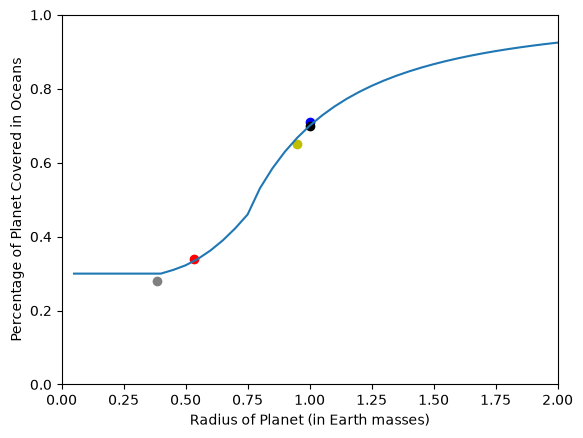

The star has a maximum apparent diameter of 0.5229675838052289 degrees.
The star has a minimum apparent diameter of 0.5407310967394133 degrees.


{'Planet': 'Earth',
 'Mass (Earth)': 1.0,
 'Radius (Earth)': 1.0,
 'Gravity (Earth)': 1.0,
 'Density (g/cm^3)': 5.51,
 'Area (Earth)': 1.0,
 'Equilibrium Temperature (K)': 254.56,
 'Semi-Major Axis (AU)': 1.0,
 'Orbital Period (days)': 365.25,
 'Eccentricity': 0.0167,
 'Surface Water Ratio': 0.7,
 'Avg. Star Angular Diamter (deg)': 0.53,
 'L1 Distance (km)': 1500837.0,
 'Escape Velocity (km/s)': 11.18,
 'Star': 'Sol',
 'Star Mass (sun)': 1.0,
 'Star Radius (sun)': 1.0,
 'Star Temperature (K)': 5778,
 'Spectral Type': 'G2V',
 'Distance (lightyears)': 0,
 'Right Ascension (degrees)': 0,
 'Declination (degrees)': 0}

In [33]:
create_dictionary("Earth", 1.000, 1.000, 1.0, 365.25, 0.0167, "Sol", 1.000, 1.000, 5778, "G2V", 0, 0, 0)